<a href="https://colab.research.google.com/github/CLAIR-LAB-TECHNION/physical-ai-workshop/blob/main/material/Day%204/CLAIR-PAI-WS-Lab-4.2-LearnedTAMP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![CLAIR, Taub Faculty of Computer Science, Technion](https://raw.githubusercontent.com/CLAIR-LAB-TECHNION/physical-ai-workshop/main/assets/workshop-banner.png)

Written by: Almog Anschel and Sarah Keren

#### Reason. Plan. Act. | Physical AI Workshop

# Tutorial 4.2: Intro to AI with deep learning and world models

In tutorials 1.1 to 4.1 we built a complete robot system by hand. A task planner turned a PDDL model into a
plan; a motion planner turned every action into a collision-free path; inverse kinematics, a controller and a state
estimator connected those paths to the robot and its camera. In the [previous tutorial](https://colab.research.google.com/github/CLAIR-LAB-TECHNION/physical-ai-workshop/blob/main/material/Day%204/CLAIR-PAI-WS-Lab-4.1-IntegratedTAMP.ipynb)
the pieces finally talked to each other in both directions. Every one of them was written by a person who understood
the problem, and every one of them could be **checked**: when Fast Downward says "solved", the plan is correct for its
model.

All of that rests on a **model** of the world that someone wrote down: the PDDL domain, the geometry, the costs. Classical
AI assumes the model; a robot has to get it. There are three ways to get it: learn the model, learn the policy, or learn
both. Today we take the system apart again, and ask of each piece: **could it be learned instead?** What would a learned
version need (data, compute), what would it gain (no hand-written model), and what would we lose (the check)? We will:

| Notebook | | What you will see |
|---|---|---|
| Tasks 1–3 | Part 1, Move | behaviour cloning fails at a fork; a flow policy does not |
| Tasks 4–6 | Part 2, See & Act | the VLA runs; pixels become tokens; one look at what it attends to |
| Tasks 7–8 | Part 3, Plan | an LLM drafts the plan, a classical checker tests it |

**Runtime.** Parts 1 and 3 run anywhere, on a CPU. Part 2 runs a 450-million-parameter network: use a **GPU runtime**
(in Colab: *Runtime → Change runtime type → T4 GPU*). The cell below says where this notebook runs; every setting that
depends on the hardware (device, number precision, batch size) is derived from it.

| stage | where it runs | how long |
|---|---|---|
| Part 1: training the small policies | anywhere (CPU is fine) | under a minute |
| Part 2: generating the demonstrations | anywhere (we ship them) | about an hour on a laptop |
| Part 2: fine-tuning SmolVLA on them | a large GPU (we ship the result) | hours |
| Part 2: running SmolVLA, opening it up | T4 GPU, a local NVIDIA GPU, or a recent Mac | about a second per decision |
| ★ Part 2: fine-tuning it yourself, briefly | T4 GPU or a local one | ~15 minutes for 300 steps |
| Part 3: replaying the LLM's recorded answers | anywhere | seconds |

In [ ]:
RUNTIME = "colab_t4"  # where this notebook runs: "colab_t4" | "local_gpu" (an NVIDIA GPU) | "mps" (a Mac with Apple silicon)

import torch

RUNTIMES = {
    "colab_t4": {"device": "cuda", "dtype": torch.float16, "batch_size": 8, "finetune_steps": 300},
    "local_gpu": {"device": "cuda", "dtype": torch.bfloat16 if torch.cuda.is_available() and torch.cuda.is_bf16_supported() else torch.float16,
                  "batch_size": 8, "finetune_steps": 300},
    "mps": {"device": "mps", "dtype": torch.float32, "batch_size": 8, "finetune_steps": 50},
}
SETTINGS = RUNTIMES[RUNTIME]
DEVICE = SETTINGS["device"]
if DEVICE == "cuda" and not torch.cuda.is_available():
    DEVICE = "mps" if torch.backends.mps.is_available() else "cpu"
if DEVICE == "mps" and not torch.backends.mps.is_available():
    DEVICE = "cpu"
DTYPE = SETTINGS["dtype"] if DEVICE == "cuda" else torch.float32
print(f"runtime {RUNTIME}: device {DEVICE}, {str(DTYPE).replace('torch.', '')}")

# Setup

This notebook is standalone: everything it needs is installed by the cells below: the planning tools of tutorials 1.1 and
4.1, MuJoCo and OMPL for tutorials 1.2 to 4.1, and [LeRobot](https://github.com/huggingface/lerobot), Hugging Face's robot
learning library, which provides SmolVLA. The demonstrations and the fine-tuned policy that Part 2 uses are large, so we
download them rather than recompute them.

In [ ]:
import sys, importlib.util

NEEDED = {"unified_planning": "unified-planning", "up_fast_downward": "up-fast-downward", "mujoco": "mujoco",
          "mediapy": "mediapy", "ur_analytic_ik": "ur-analytic-ik", "ompl": "ompl>=2.0", "gdown": "gdown",
          "lerobot": "lerobot[smolvla,dataset]==0.6.1"}  # module: what pip installs
IN_COLAB = importlib.util.find_spec("google.colab") is not None
missing = [package for module, package in NEEDED.items() if importlib.util.find_spec(module) is None]
if IN_COLAB or missing:  # %pip installs into this kernel's Python, whatever "pip" on the PATH is
    if sys.version_info >= (3, 14):
        print(f"ompl has wheels for Python 3.10 to 3.13 only; this kernel runs {sys.version.split()[0]}")
    %pip install -q unified-planning up-fast-downward mujoco mediapy ur-analytic-ik "ompl>=2.0" gdown "lerobot[smolvla,dataset]==0.6.1"
else:
    print("packages already installed, skipping")
if IN_COLAB:  # the videos need ffmpeg; Colab's image lacks it
    !command -v ffmpeg >/dev/null || (apt-get -qq update && apt-get -qq install -y ffmpeg)

**Where the data comes from.** The demonstrations, the fine-tuned policy, the recorded LLM answers and a few clips sit in
a shared Drive folder, `physical-ai-day4`. Two ways to get them, by where you run: on **Colab**, the cell mounts your
Drive and uses the shared folder in place, nothing to download, if you first open the folder's link and choose *Add
shortcut to Drive* (into *My Drive*); anywhere else, or without the shortcut, the cell downloads the folder once (a few
GB) into `data/wednesday`.

In [ ]:
#@title Helper: the demonstrations, the fine-tuned policy and the recorded answers { display-mode: "form" }
import importlib.util
import os

DATA_DIR = "data/wednesday"
DRIVE_FOLDER = "https://drive.google.com/drive/folders/1Wyr0zB5CAC3JIX59iOWXLLn-g4db2GCO"  # the shared folder physical-ai-day4
SHARED_IN_DRIVE = "/content/drive/MyDrive/physical-ai-day4"  # where the shared folder appears once you add a shortcut to it

if not os.path.exists(DATA_DIR):
    os.makedirs(os.path.dirname(DATA_DIR), exist_ok=True)
    if importlib.util.find_spec("google.colab") is not None:  # on Colab: mount your Drive, use the shared folder in place
        from google.colab import drive
        drive.mount("/content/drive")
        if os.path.isdir(SHARED_IN_DRIVE):
            os.symlink(SHARED_IN_DRIVE, DATA_DIR)
        else:
            print(f"{SHARED_IN_DRIVE} not found: add a shortcut to the shared folder physical-ai-day4 in your Drive, "
                  "or wait for the download below")
    if not os.path.exists(DATA_DIR):  # anywhere else, or no shortcut: download the folder once
        import gdown
        gdown.download_folder(DRIVE_FOLDER, output=DATA_DIR, quiet=False)
print(sorted(os.listdir(DATA_DIR)))

The robot, its tables and the tools of tutorials 1.2 to 3.2 (MuJoCo scene, IK, RRT, the skills) come next, as collapsed
cells, exactly as in tutorial 4.1: Part 1 learns from them, Part 2 replaces them.

In [ ]:
#@title Helper: off-screen rendering setup { display-mode: "form" }
import os
import platform
import subprocess

if platform.system() != "Darwin":  # on macOS, MuJoCo uses the native OpenGL implementation
    try:
        has_gpu = subprocess.run("nvidia-smi", capture_output=True).returncode == 0
    except FileNotFoundError:
        has_gpu = False
    if has_gpu:
        # Colab GPU runtimes lack the config file that lets OpenGL find the NVIDIA EGL driver. Create it.
        NVIDIA_ICD_CONFIG_PATH = "/usr/share/glvnd/egl_vendor.d/10_nvidia.json"
        if not os.path.exists(NVIDIA_ICD_CONFIG_PATH):
            os.makedirs(os.path.dirname(NVIDIA_ICD_CONFIG_PATH), exist_ok=True)
            with open(NVIDIA_ICD_CONFIG_PATH, "w") as f:
                f.write('{"file_format_version": "1.0.0", "ICD": {"library_path": "libEGL_nvidia.so.0"}}')
    os.environ["MUJOCO_GL"] = "egl"  # off-screen rendering (software-rendered if there is no GPU)

In [ ]:
import os

if not os.path.exists("mujoco_menagerie/universal_robots_ur5e"):
    !git clone -q --depth 1 --filter=blob:none --sparse https://github.com/google-deepmind/mujoco_menagerie
    !cd mujoco_menagerie && git sparse-checkout set universal_robots_ur5e

UR5E_XML = "mujoco_menagerie/universal_robots_ur5e/ur5e.xml"

In [ ]:
import time

import matplotlib.pyplot as plt
import mediapy as media
import mujoco
import numpy as np

np.set_printoptions(precision=3, suppress=True)  # print numbers with 3 decimals

In [ ]:
#@title Helper: the N-Table Blocks World and the tools from tutorials 1.2 to 3.1 { display-mode: "form" }

SCENE_XML = """
<mujoco model="ntbw">
  <option integrator="implicitfast"/>

  <visual>
    <headlight diffuse="0.6 0.6 0.6" ambient="0.3 0.3 0.3" specular="0 0 0"/>
    <rgba haze="0.15 0.25 0.35 1"/>
  </visual>

  <asset>
    <texture type="skybox" builtin="gradient" rgb1="0.3 0.5 0.7" rgb2="0 0 0" width="512" height="3072"/>
    <texture type="2d" name="groundplane" builtin="checker" mark="edge" rgb1="0.2 0.3 0.4" rgb2="0.1 0.2 0.3"
             markrgb="0.8 0.8 0.8" width="300" height="300"/>
    <material name="groundplane" texture="groundplane" texuniform="true" texrepeat="5 5" reflectance="0.2"/>
    <material name="table" rgba="0.75 0.75 0.75 1"/>
    <material name="pedestal" rgba="0.2 0.2 0.2 1"/>
  </asset>

  <!-- MuJoCo box sizes are HALF sizes: table tops are 60cm x 60cm x 2cm -->
  <default>
    <default class="table_top">
      <geom type="box" size="0.3 0.3 0.01" pos="0 0 0.71" material="table"/>
    </default>
    <default class="table_leg">
      <geom type="cylinder" size="0.02 0.35" material="table"/>
    </default>
  </default>

  <worldbody>
    <light pos="0 0 2.5" dir="0 0 -1" directional="true"/>
    <geom name="floor" size="0 0 0.05" type="plane" material="groundplane"/>

    <!-- the robot will be attached to this site, at the top of the pedestal (turned to face table t2) -->
    <body name="mount" pos="0 0 0.75" euler="0 0 180">
      <geom name="pedestal" type="cylinder" size="0.12 0.375" pos="0 0 -0.375" material="pedestal"/>
      <site name="mount_site"/>
    </body>

    <!-- three tables, named as in the PDDL problem of tutorial 1.1 -->
    <body name="t1" pos="0 -0.65 0">
      <geom name="t1_top" class="table_top"/>
      <geom class="table_leg" pos="0.26 -0.26 0.35"/>
      <geom class="table_leg" pos="0.26 0.26 0.35"/>
      <geom class="table_leg" pos="-0.26 -0.26 0.35"/>
      <geom class="table_leg" pos="-0.26 0.26 0.35"/>
    </body>
    <body name="t2" pos="0.65 0 0">
      <geom name="t2_top" class="table_top"/>
      <geom class="table_leg" pos="0.26 -0.26 0.35"/>
      <geom class="table_leg" pos="0.26 0.26 0.35"/>
      <geom class="table_leg" pos="-0.26 -0.26 0.35"/>
      <geom class="table_leg" pos="-0.26 0.26 0.35"/>
    </body>
    <body name="t3" pos="0 0.65 0">
      <geom name="t3_top" class="table_top"/>
      <geom class="table_leg" pos="0.26 -0.26 0.35"/>
      <geom class="table_leg" pos="0.26 0.26 0.35"/>
      <geom class="table_leg" pos="-0.26 -0.26 0.35"/>
      <geom class="table_leg" pos="-0.26 0.26 0.35"/>
    </body>

    <!-- cameras to watch the scene from -->
    <camera name="overview" mode="targetbody" target="mount" pos="1.9 -1.9 1.9"/>
    <camera name="front" mode="targetbody" target="mount" pos="2.4 0 1.5"/>
    <camera name="side" mode="targetbody" target="mount" pos="0 -2.4 1.5"/>
    <camera name="top" pos="0 0 3.0" xyaxes="0 1 0 -1 0 0"/>
    <!-- the RGB-D camera of tutorial 3.1: on the ceiling, looking straight down at the three tables -->
    <camera name="ceiling" pos="0.3 0 2.05" xyaxes="0 1 0 -1 0 0" fovy="58"/>
  </worldbody>
</mujoco>
"""

TABLES = ["t1", "t2", "t3"]
BLOCK_HALF_HEIGHT = 0.02
BLOCK_HALF_WIDTH = 0.04  # the blocks are 8cm x 8cm x 4cm
COLORS = {"yellow": [1, 0.9, 0, 1], "blue": [0.1, 0.3, 1, 1], "green": [0.1, 0.8, 0.2, 1], "red": [1, 0.1, 0.1, 1]}

# a layout says which blocks there are: name -> (color, position of the center). This is the scene of tutorials 1.1 to 3.2.
DEFAULT_LAYOUT = {
    "b1": ("yellow", [0.05, -0.6, 0.74]),
    "b2": ("blue", [0.05, -0.6, 0.78]),
    "b3": ("yellow", [0.6, 0.1, 0.74]),
    "b4": ("green", [-0.1, 0.55, 0.74]),
    "b5": ("red", [0.15, 0.7, 0.74]),
}

TOOL_XML = """
<mujoco model="suction_gripper">
  <worldbody>
    <body name="suction_cup">
      <geom name="suction_cup" type="cylinder" size="0.02 0.03" pos="0 0 0.03" rgba="0.3 0.3 0.3 1" mass="0.05"/>
      <site name="tcp" pos="0 0 0.06" size="0.005" rgba="1 0 0 1"/>
    </body>
  </worldbody>
</mujoco>
"""

# a wall with a window (a serving hatch) between the robot and table t1: name, half sizes, position
WINDOW_GEOMS = [
    ("window_sill", [0.30, 0.01, 0.10], [0.00, -0.34, 0.82]),
    ("window_post_left", [0.02, 0.02, 0.30], [-0.28, -0.34, 1.02]),
    ("window_post_right", [0.02, 0.02, 0.30], [0.28, -0.34, 1.02]),
    ("window_lintel", [0.30, 0.02, 0.02], [0.00, -0.34, 1.30]),
]


def build_model(layout, window=True):
    scene = mujoco.MjSpec.from_string(SCENE_XML)
    robot = mujoco.MjSpec.from_file(UR5E_XML)
    tool = mujoco.MjSpec.from_string(TOOL_XML)

    scene.attach(robot, site="mount_site", prefix="robot_")
    scene.attach(tool, site="robot_attachment_site", prefix="tool_")

    for block, (color, position) in layout.items():
        body = scene.worldbody.add_body(name=block, pos=position)
        body.add_freejoint(name=f"{block}_joint")  # a freejoint lets a body move freely
        body.add_geom(name=block, type=mujoco.mjtGeom.mjGEOM_BOX, size=[BLOCK_HALF_WIDTH, BLOCK_HALF_WIDTH, BLOCK_HALF_HEIGHT],
                      mass=0.1, rgba=COLORS[color])
        # one (inactive) weld constraint per block, for our simplified suction gripper
        scene.add_equality(name=f"grasp_{block}", type=mujoco.mjtEq.mjEQ_WELD, objtype=mujoco.mjtObj.mjOBJ_BODY,
                           name1="tool_suction_cup", name2=block, active=False)

    if window:
        for name, size, pos in WINDOW_GEOMS:
            scene.worldbody.add_geom(name=name, type=mujoco.mjtGeom.mjGEOM_BOX, size=size, pos=pos, rgba=[0.6, 0.4, 0.2, 1])

    return scene.compile()


ROBOT_JOINTS = ["shoulder_pan_joint", "shoulder_lift_joint", "elbow_joint", "wrist_1_joint", "wrist_2_joint", "wrist_3_joint"]
ROBOT_ACTUATORS = ["shoulder_pan", "shoulder_lift", "elbow", "wrist_1", "wrist_2", "wrist_3"]
HOME = np.array([0, -np.pi / 2, np.pi / 2, -np.pi / 2, -np.pi / 2, 0])
renderer = None


def load_scene(layout=DEFAULT_LAYOUT, window=True):
    """Build the world with the given blocks (new in this tutorial: the scene can be replaced by another one)."""
    global BLOCKS, BLOCK_COLORS, model, data, renderer, qpos_idx, qvel_idx, ctrl_idx
    BLOCKS = list(layout)
    BLOCK_COLORS = {block: color for block, (color, _) in layout.items()}
    model = build_model(layout, window)  # MjModel: everything that does not change during simulation (geometry, masses, ...)
    data = mujoco.MjData(model)  # MjData: everything that does (positions, velocities, contacts, ...)
    if renderer is not None:
        renderer.close()
    renderer = mujoco.Renderer(model, height=480, width=640)
    qpos_idx = np.array([model.joint("robot_" + name).qposadr[0] for name in ROBOT_JOINTS])
    qvel_idx = np.array([model.joint("robot_" + name).dofadr[0] for name in ROBOT_JOINTS])
    ctrl_idx = np.array([model.actuator("robot_" + name).id for name in ROBOT_ACTUATORS])
    reset()


def render(camera="overview", scene_option=None):
    """An RGB image of the current state of the simulation, seen from the named camera."""
    renderer.update_scene(data, camera=camera, scene_option=scene_option)
    return renderer.render()


def show_video(frames, fps=30):
    if len(frames) == 0:
        print("(no frames to show)")
    else:
        media.show_video(frames, fps=fps)


def get_configuration():
    """The robot's joint angles (radians)."""
    return data.qpos[qpos_idx].copy()


def get_joint_velocities():
    return data.qvel[qvel_idx].copy()


def get_block_positions():
    """The position of the center of every block, in world coordinates."""
    return {block: data.body(block).xpos.copy() for block in BLOCKS}


def move_to(target, tolerance=0.03, max_steps=2000, render_every=50, camera="overview"):
    """Apply the target configuration until the robot reaches it (within tolerance, radians) and stops moving.

    Returns (success, frames): whether the target was reached, and video frames of the motion.
    """
    frames = []
    for i in range(max_steps):
        data.ctrl[ctrl_idx] = target
        mujoco.mj_step(model, data)
        if i % render_every == 0:
            frames.append(render(camera))
        if np.linalg.norm(get_configuration() - target) < tolerance and np.linalg.norm(get_joint_velocities()) < 0.05:
            return True, frames
    return False, frames


def follow_path(waypoints, tolerance=0.1, max_steps_per_waypoint=500, render_every=50, camera="overview"):
    """Move the robot along the path (tutorial 2.1: switch to the next waypoint when close enough). Returns (success, frames)."""
    frames = []
    step = 0
    for i, target in enumerate(waypoints):
        if i == len(waypoints) - 1:  # stop precisely at the last waypoint
            success, new_frames = move_to(target, render_every=render_every, camera=camera)
            return success, frames + new_frames
        for _ in range(max_steps_per_waypoint):
            data.ctrl[ctrl_idx] = target
            mujoco.mj_step(model, data)
            if step % render_every == 0:
                frames.append(render(camera))
            step += 1
            if np.linalg.norm(get_configuration() - target) < tolerance:
                break  # close enough, on to the next waypoint
        else:
            return False, frames  # the robot got stuck
    return True, frames


def go_to(q_goal):
    """Plan a path from the current configuration to q_goal and follow it. Returns (success, frames)."""
    waypoints = plan(get_configuration(), q_goal, verbose=False)
    if waypoints is None:
        print("no path found")
        return False, []
    return follow_path(waypoints)


def reset():
    """Reset the simulation to the initial state, with the robot at the home configuration."""
    mujoco.mj_resetData(model, data)
    data.qpos[qpos_idx] = HOME
    data.ctrl[ctrl_idx] = HOME  # the home configuration as the servos' target
    data.eq_active[:] = 0  # no block is grasped
    mujoco.mj_forward(model, data)


def set_configuration(q):
    """Teleport the robot to configuration q. This only updates kinematics, no physics is simulated."""
    data.qpos[qpos_idx] = q
    mujoco.mj_forward(model, data)


def get_tcp_position():
    return data.site("tool_tcp").xpos.copy()


def get_tcp_pose():
    """Position (3,) and orientation (3x3 rotation matrix) of the tool center point in the world frame."""
    site = data.site("tool_tcp")
    return site.xpos.copy(), site.xmat.reshape(3, 3).copy()


def transformation(position, quaternion):
    """The 4x4 homogeneous transformation of a pose given as position and unit quaternion (w, x, y, z)."""
    rotation = np.zeros(9)
    mujoco.mju_quat2Mat(rotation, quaternion)
    T = np.eye(4)
    T[:3, :3] = rotation.reshape(3, 3)
    T[:3, 3] = position
    return T


def wrap_angles(q):
    """Wrap angles to [-pi, pi]. Joint angles are periodic, and this keeps them inside the robot's joint limits."""
    return (q + np.pi) % (2 * np.pi) - np.pi


FACING_DOWN = np.array([[1, 0, 0],
                        [0, -1, 0],
                        [0, 0, -1]])

from ur_analytic_ik import ur5e


def world_to_base(position, rotation):
    """Transform a pose from world coordinates to the robot's base frame."""
    base = data.body("mount")
    base_position, base_rotation = base.xpos, base.xmat.reshape(3, 3)
    return base_rotation.T @ (position - base_position), base_rotation.T @ rotation


T_TOOL = np.eye(4)
T_TOOL[2, 3] = 0.06  # the tcp site relative to the flange: 6 cm out, at the tip of the suction cup


def analytical_ik(target_position, target_rotation):
    """All configurations that bring the tool center point to the target pose (world frame). Empty if unreachable."""
    position, rotation = world_to_base(target_position, target_rotation)
    T_flange = np.eye(4)
    T_flange[:3, :3] = rotation
    T_flange[:3, 3] = position
    return ur5e.inverse_kinematics_with_tcp(T_flange, T_TOOL)


def grasped_block():
    """The block currently held by the suction cup, or None."""
    for block in BLOCKS:
        if data.eq_active[model.equality(f"grasp_{block}").id]:
            return block
    return None


def body_of_geom(geom_id):
    """The name of the body a geom belongs to (the robot's collision geoms have no names of their own)."""
    return model.body(model.geom(geom_id).bodyid[0]).name


def in_collision(q):
    """Whether the robot (or its tool) is in contact with anything when placed at configuration q.

    The robot is teleported to q for the check and then put back where it was.
    """
    current = get_configuration()
    set_configuration(q)
    held = grasped_block()  # a grasped block touches the cup by design
    collision = False
    for i in range(data.ncon):
        contact = data.contact[i]
        body1, body2 = body_of_geom(contact.geom1), body_of_geom(contact.geom2)
        if held in (body1, body2):
            continue
        if body1.startswith(("robot_", "tool_")) or body2.startswith(("robot_", "tool_")):
            collision = True
            break
    set_configuration(current)
    return collision


def nearest_equivalent(q, reference):
    """Shift each angle of q by a multiple of 2*pi to the equivalent angle nearest to reference, within [-pi, pi].

    (Tutorials 1.2 to 3.1 allowed the full +-2*pi range of the UR5e joints here; we keep every configuration within the
    bounds of the motion planner, so that a planned motion can start wherever the previous one ended.)
    """
    shifted = reference + wrap_angles(q - reference)
    within_limits = (shifted >= JOINT_BOUNDS[:, 0]) & (shifted <= JOINT_BOUNDS[:, 1])
    return np.where(within_limits, shifted, wrap_angles(q))


def choose_solution(solutions, reference):
    """The collision-free solution closest to the reference configuration, or None if there is none."""
    free = [nearest_equivalent(q, reference) for q in solutions if not in_collision(q)]
    if not free:
        return None
    return min(free, key=lambda q: np.linalg.norm(q - reference))


def pose_above(block, height=0.1):
    """The tcp pose `height` meters above the top of the block, facing down."""
    top = data.body(block).xpos + [0, 0, BLOCK_HALF_HEIGHT]
    return top + [0, 0, height], FACING_DOWN


def grasp(max_distance=0.03):
    """Activate the suction: weld the block whose top is within max_distance of the tcp to the cup. Returns the block or None."""
    tcp = get_tcp_position()
    cup = data.body("tool_suction_cup")
    for block in BLOCKS:
        body = data.body(block)
        if np.linalg.norm(body.xpos + [0, 0, BLOCK_HALF_HEIGHT] - tcp) < max_distance:
            # the weld keeps the block at its current pose relative to the cup
            relative_position = cup.xmat.reshape(3, 3).T @ (body.xpos - cup.xpos)
            cup_quat_inverse, relative_quat = np.zeros(4), np.zeros(4)
            mujoco.mju_negQuat(cup_quat_inverse, cup.xquat)
            mujoco.mju_mulQuat(relative_quat, cup_quat_inverse, body.xquat)
            equality = model.equality(f"grasp_{block}")
            model.eq_data[equality.id] = np.concatenate([[0, 0, 0], relative_position, relative_quat, [1.0]])
            data.eq_active[equality.id] = 1
            return block
    return None


def release():
    """Deactivate the suction."""
    data.eq_active[:] = 0


def interpolate(q_from, q_to, n_steps):
    """n_steps configurations evenly spaced on the straight line from q_from to q_to (inclusive)."""
    return [q_from + t * (q_to - q_from) for t in np.linspace(0, 1, n_steps)]


def path_in_collision(q_from, q_to, n_steps=50):
    """Whether the straight line in configuration space from q_from to q_to passes through a collision."""
    return any(in_collision(q) for q in interpolate(q_from, q_to, n_steps))

# --- planning while holding a block (tutorial 2.1) ---

def set_configuration(q):
    """Teleport the robot, and the block it holds (if any), to configuration q. No physics is simulated."""
    data.qpos[qpos_idx] = q
    block = grasped_block()
    if block is not None:
        mujoco.mj_kinematics(model, data)  # where is the cup now?
        cup = data.body("tool_suction_cup")
        weld_data = model.eq_data[model.equality(f"grasp_{block}").id]
        relative_position, relative_quat = weld_data[3:6], weld_data[6:10]  # the block's pose in the cup's frame

        position = cup.xpos + cup.xmat.reshape(3, 3) @ relative_position
        quat = np.zeros(4)
        mujoco.mju_mulQuat(quat, cup.xquat, relative_quat)

        address = model.joint(f"{block}_joint").qposadr[0]  # where the block's free joint lives in qpos
        data.qpos[address:address + 3] = position
        data.qpos[address + 3:address + 7] = quat
    mujoco.mj_forward(model, data)


def robot_in_collision():
    """Whether the robot, its tool, or the block it holds currently touches anything (other than each other)."""
    held = grasped_block()
    for i in range(data.ncon):
        contact = data.contact[i]
        body1, body2 = body_of_geom(contact.geom1), body_of_geom(contact.geom2)
        if held is not None and {body1, body2} == {held, "tool_suction_cup"}:
            continue  # the held block touches the cup by design
        if body1.startswith(("robot_", "tool_")) or body2.startswith(("robot_", "tool_")) or held in (body1, body2):
            return True
    return False


def in_collision(q):
    """Whether the robot (with the block it holds, if any) is in contact with anything when placed at configuration q."""
    snapshot = data.qpos.copy()
    set_configuration(q)
    collision = robot_in_collision()
    data.qpos[:] = snapshot
    mujoco.mj_forward(model, data)
    return collision


# --- motion planning with OMPL (tutorial 2.1) ---

from ompl import base as ob
from ompl import geometric as og
from ompl import util as ou

ou.setLogLevel(ou.LogLevel.LOG_WARN)  # OMPL is chatty; set LOG_INFO to see what the planners are up to


def make_state(space, values):
    state = space.allocState()
    state[:len(values)] = [float(v) for v in values]
    return state


def iterations(n):
    """A termination condition that stops the planner after n iterations."""
    count = [0]

    def done():
        count[0] += 1
        return count[0] > n

    return ob.PlannerTerminationCondition(done)


def path_to_array(path, dimension):
    """The waypoints of an OMPL path as an array of shape (n_waypoints, dimension)."""
    return np.array([path.getState(i)[:dimension] for i in range(path.getStateCount())])


import random


def set_seed(seed):
    """Seed every source of randomness we use: Python, NumPy and OMPL. Use it right before creating a planner."""
    random.seed(seed)
    np.random.seed(seed)
    log_level = ou.getLogLevel()
    ou.setLogLevel(ou.LogLevel.LOG_NONE)  # silence OMPL's complaint about being seeded again
    ou.RNG.setSeed(seed)
    ou.setLogLevel(log_level)


JOINT_BOUNDS = np.array([[-np.pi, np.pi]] * 6)  # the UR5e joints turn +-2*pi; we plan (and move) within +-pi


def make_arm_space():
    space = ob.RealVectorStateSpace(6)
    bounds = ob.RealVectorBounds(6)
    for i, (low, high) in enumerate(JOINT_BOUNDS):
        bounds.setLow(i, float(low))
        bounds.setHigh(i, float(high))
    space.setBounds(bounds)
    return space


def is_valid_configuration(state):
    set_configuration(state[:6])
    return not robot_in_collision()


def plan(q_start, q_goal, planner_type=og.RRTConnect, max_iterations=20000, resolution=0.002, simplify=True, spacing=0.05, verbose=True):
    """Plan a collision-free path from q_start to q_goal. Returns a list of waypoints (start and goal included) or None."""
    snapshot = data.qpos.copy()  # the validity checks teleport the robot; we put everything back at the end

    # the configuration space and its free space
    space = make_arm_space()
    space_info = ob.SpaceInformation(space)
    space_info.setStateValidityChecker(is_valid_configuration)
    space_info.setStateValidityCheckingResolution(resolution)
    space_info.setup()

    # the problem: from the start to the goal. Angles are periodic, so we may wrap the goal into the bounds.
    problem = ob.ProblemDefinition(space_info)
    problem.setStartAndGoalStates(make_state(space, q_start), make_state(space, wrap_angles(q_goal)))

    # the planner
    planner = planner_type(space_info)
    planner.setProblemDefinition(problem)
    planner.setup()

    start_time = time.time()
    status = planner.solve(ob.plannerOrTerminationCondition(iterations(max_iterations), ob.exactSolnPlannerTerminationCondition(problem)))
    planning_time = time.time() - start_time

    waypoints = None
    if status.getStatus() == ob.PlannerStatus.PlannerStatusType.EXACT_SOLUTION:
        path = problem.getSolutionPath()
        raw_length = path.length()
        if simplify:
            og.PathSimplifier(space_info).simplify(path, 0.0)
        if spacing is not None:
            path.interpolate(max(2, int(np.ceil(path.length() / spacing))))
        waypoints = list(path_to_array(path, 6))
        if verbose:
            print(f"{planner.getName()}: {status.asString()} in {planning_time:.2f}s, path length {raw_length:.2f} rad"
                  + (f" ({path.length():.2f} after simplification)" if simplify else "") + f", {len(waypoints)} waypoints")
    elif verbose:
        print(f"{planner.getName()}: {status.asString()} after {planning_time:.2f}s")

    data.qpos[:] = snapshot
    mujoco.mj_forward(model, data)
    return waypoints


load_scene()

In [ ]:
#@title Helper: the decoupled task and motion planning system of tutorial 3.2 { display-mode: "form" }
import matplotlib.pyplot as plt
import unified_planning as up
from unified_planning.io import PDDLReader
from unified_planning.shortcuts import OneshotPlanner, SequentialSimulator, get_environment

get_environment().credits_stream = None  # keep the output clean (planners print their credits otherwise)

# --- the task planner's model (tutorial 1.1) ---

NTBW_DOMAIN = """
(define (domain n-table-blocks-world)
  (:requirements :strips :typing)
  (:types block color table)
  (:predicates (on ?b1 ?b2 - block)
               (ontable ?b - block ?t - table)
               (clear ?b - block)
               (handempty)
               (holding ?b - block)
               (bcolor ?b - block ?c - color))

  (:action pick-up
     :parameters (?b - block ?t - table)
     :precondition (and (clear ?b) (ontable ?b ?t) (handempty))
     :effect (and (not (ontable ?b ?t)) (not (clear ?b)) (not (handempty)) (holding ?b)))

  (:action put-down
     :parameters (?b - block ?t - table)
     :precondition (holding ?b)
     :effect (and (not (holding ?b)) (clear ?b) (handempty) (ontable ?b ?t)))

  (:action stack
     :parameters (?b1 ?b2 - block)
     :precondition (and (holding ?b1) (clear ?b2))
     :effect (and (not (holding ?b1)) (not (clear ?b2)) (clear ?b1) (handempty) (on ?b1 ?b2)))

  (:action unstack
     :parameters (?b1 ?b2 - block)
     :precondition (and (on ?b1 ?b2) (clear ?b1) (handempty))
     :effect (and (holding ?b1) (clear ?b2) (not (clear ?b1)) (not (handempty)) (not (on ?b1 ?b2))))
)
"""

PROBLEM_TEMPLATE = """
(define (problem ntbw)
  (:domain n-table-blocks-world)
  (:objects {blocks} - block  {colors} - color  {tables} - table)
  (:init {init})
  (:goal {goal})
  {metric})
"""


# --- the state estimator (tutorial 3.1): the true state, read from the simulator's contacts ---

def true_state():
    """The facts that actually hold in the simulation, from the contacts between the blocks and what they rest on."""
    held = grasped_block()
    support = {}  # block -> the block or table it rests on
    for i in range(data.ncon):
        contact = data.contact[i]
        body1, body2 = body_of_geom(contact.geom1), body_of_geom(contact.geom2)
        normal = contact.frame[:3]  # the contact normal, pointing from geom1 to geom2
        for upper, lower, direction in [(body2, body1, normal), (body1, body2, -normal)]:
            if upper in BLOCKS and upper != held and lower in BLOCKS + TABLES and direction[2] > 0.9:
                support[upper] = lower
    facts = {("holding", held)} if held is not None else {("handempty",)}
    for block, lower in support.items():
        facts.add(("ontable", block, lower) if lower in TABLES else ("on", block, lower))
    for block in BLOCKS:
        if block != held and block not in support.values():
            facts.add(("clear", block))
    return facts


def settle(duration=0.2):
    """Let the simulation run (with the servos holding their targets) for the given time."""
    for _ in range(round(duration / model.opt.timestep)):
        mujoco.mj_step(model, data)


def estimate_state():
    """The abstract state of the world, as our state estimator sees it."""
    settle()
    return true_state()


def fact_string(fact):
    return "(" + " ".join(fact) + ")"


def print_state(facts):
    print("  " + "  ".join(fact_string(fact) for fact in sorted(facts)))


# --- facts in and out of the planner ---

def facts_of(state, problem):
    """The facts that hold in a state of the planner, as tuples (without the colors, which never change)."""
    facts = set()
    for expression in problem.initial_values:  # lists every grounded fluent, which is a convenient way to enumerate them all
        if expression.type.is_bool_type() and expression.fluent().name != "bcolor" and state.get_value(expression).is_true():
            facts.add((expression.fluent().name,) + tuple(str(arg) for arg in expression.args))
    return facts


def goal_holds(problem):
    """Whether the goal of a problem holds in its initial state."""
    with SequentialSimulator(problem) as simulator:
        return simulator.is_goal(simulator.get_initial_state())


def make_problem(facts, goal, domain=NTBW_DOMAIN, numbers=None):
    """A planning problem whose initial state is the given set of facts and whose goal is the given PDDL expression.

    numbers gives the values of numeric functions, for domains with action costs: {("access-cost", "t1"): 5, ...}.
    """
    color_facts = {("bcolor", block, color) for block, color in BLOCK_COLORS.items()}
    init = " ".join(fact_string(fact) for fact in sorted(facts | color_facts))
    metric = ""
    if numbers is not None:
        init += " (= (total-cost) 0) " + " ".join(f"(= {fact_string(function)} {value})" for function, value in numbers.items())
        metric = "(:metric minimize (total-cost))"
    text = PROBLEM_TEMPLATE.format(blocks=" ".join(BLOCKS), colors=" ".join(COLORS), tables=" ".join(TABLES), init=init, goal=goal, metric=metric)
    return PDDLReader().parse_problem_string(domain, text)


def solve(problem):
    """An optimal plan for the problem (a list of action instances), or None if there is none."""
    with OneshotPlanner(name="fast-downward-opt") as planner:
        planner.skip_checks = True  # needed for action costs, see tutorial 1.1
        result = planner.solve(problem)
    return None if result.plan is None else list(result.plan.actions)


def expected_states(problem, task_plan):
    """The facts that the task planner expects to hold after each action of the plan (a list of sets)."""
    states = []
    with SequentialSimulator(problem) as simulator:
        state = simulator.get_initial_state()
        for action in task_plan:
            state = simulator.apply(state, action)
            states.append(facts_of(state, problem))
    return states


# --- skills: from actions to motions ---

APPROACH_HEIGHT = 0.1  # meters: the tool hovers this high above the target before descending straight down
GRASP_CLEARANCE = 0.005  # the suction cup grasps from 5 mm above the block
PLACE_CLEARANCE = 0.01  # and lets go from 1 cm above the surface


def block_top(block):
    """The center of the top face of a block."""
    return data.body(block).xpos + [0, 0, BLOCK_HALF_HEIGHT]


def approach_configurations(target, low, high=APPROACH_HEIGHT):
    """Configurations for being `low` above the target (grasping or releasing) and for hovering `high` above it.

    Both are collision-free and in the same IK family, so that the straight-line motion between them is short (the
    descent and the lift). The low configuration is chosen first, as close as possible to where the robot is now, and
    the hovering one is the solution closest to it; if that is far (another family), the next low candidate is tried.
    Returns (q_high, q_low), or (None, None) if there is no such pair.
    """
    reference = get_configuration()
    lows = [nearest_equivalent(q, reference) for q in analytical_ik(target + [0, 0, low], FACING_DOWN) if not in_collision(q)]
    highs = [q for q in analytical_ik(target + [0, 0, high], FACING_DOWN) if not in_collision(q)]
    for q_low in sorted(lows, key=lambda q: np.linalg.norm(q - reference)):
        candidates = [nearest_equivalent(q, q_low) for q in highs]
        q_high = min(candidates, key=lambda q: np.linalg.norm(q - q_low), default=None)
        if q_high is not None and np.linalg.norm(q_high - q_low) < 1.0:
            return q_high, q_low
    return None, None


def pick_configurations(block):
    """The hovering and grasping configurations for picking up a block, or (None, None)."""
    return approach_configurations(block_top(block), GRASP_CLEARANCE)


def place_configurations(target_top):
    """The hovering and releasing configurations for putting the held block down with its bottom on target_top, or (None, None)."""
    block_height = 2 * BLOCK_HALF_HEIGHT
    return approach_configurations(target_top, block_height + PLACE_CLEARANCE, block_height + APPROACH_HEIGHT)


def pick_up(block):
    """The skill for pick-up and unstack: approach the block from above, descend, grasp, lift. Returns (success, frames)."""
    q_high, q_low = pick_configurations(block)
    if q_high is None:
        print(f"  cannot reach {block}")
        return False, []
    success, frames = go_to(q_high)  # planned motion, possibly around obstacles
    if not success:
        return False, frames
    success, new_frames = move_to(q_low)  # straight down
    frames += new_frames
    if not success:
        return False, frames
    grasped = grasp()
    success, new_frames = move_to(q_high)  # straight up
    return success and grasped == block, frames + new_frames


def place(target_top):
    """The skill for put-down and stack: put the held block down with its bottom on target_top (a point in the world)."""
    q_high, q_low = place_configurations(target_top)
    if q_high is None:
        print("  cannot reach the target")
        return False, []
    success, frames = go_to(q_high)
    if not success:
        return False, frames
    success, new_frames = move_to(q_low)
    frames += new_frames
    if not success:  # something is in the way: keep the block and back off
        _, new_frames = move_to(q_high)
        return False, frames + new_frames
    release()
    success, new_frames = move_to(q_high)
    return success, frames + new_frames


def stack(block, on_block):
    """The skill for stack: put the held block on top of on_block."""
    return place(block_top(on_block))


# --- the sampler: where to put a block down ---

MARGIN = 0.02  # a safety margin between blocks
MAX_REACH = 0.8  # meters from the robot's base: further out, the arm is stretched to its limit


def table_surface(table):
    """The height of the top face of a table, and the (x, y) center and half extents of the top."""
    top = model.geom(f"{table}_top")
    return data.geom(f"{table}_top").xpos[2] + top.size[2], data.geom(f"{table}_top").xpos[:2].copy(), top.size[:2].copy()


def table_point(table, xy):
    """The point on the surface of the table at (x, y)."""
    return np.array([xy[0], xy[1], table_surface(table)[0]])


def sample_on_table(table):
    """A uniformly random (x, y) on the table, far enough from the edges for a block to sit fully on it."""
    _, center, half_size = table_surface(table)
    return center + np.random.uniform(-1, 1, size=2) * (half_size - BLOCK_HALF_WIDTH)


def is_free(xy, exclude=None):
    """Whether a block put down at (x, y) would overlap none of the blocks on the tables (with a safety margin)."""
    for block, position in get_block_positions().items():
        if block != exclude and np.all(np.abs(position[:2] - xy) < 2 * BLOCK_HALF_WIDTH + MARGIN):
            return False
    return True


def is_reachable(table, xy):
    """Whether the spot is well within the arm's reach and the robot has collision-free configurations for placing a block there."""
    if np.linalg.norm(xy) > MAX_REACH:  # the robot's base is at the origin
        return False
    q_high, q_low = place_configurations(table_point(table, xy))
    return q_high is not None


def sample_free_spot(table, block, max_attempts=1000):
    """A free, reachable (x, y) on the table for the block, or None if none was found in max_attempts samples."""
    for _ in range(max_attempts):
        xy = sample_on_table(table)
        if is_free(xy, exclude=block) and is_reachable(table, xy):
            return xy
    return None


def put_down(block, table, xy):
    """The skill for put-down: put the held block on the table at (x, y)."""
    return place(table_point(table, xy))


# --- executing plans, with monitoring and replanning ---

def execute_action(action, sampler=sample_free_spot):
    """Run the skill that implements one action instance of the task planner. Returns (success, frames)."""
    name, args = action.action.name, [str(p) for p in action.actual_parameters]
    if name in ("pick-up", "unstack"):
        return pick_up(args[0])
    if name == "stack":
        return stack(args[0], args[1])
    if name == "put-down":
        block, table = args[0], args[1]
        xy = sampler(table, block)
        if xy is None:
            print(f"  no free spot on {table}")
            return False, []
        return put_down(block, table, xy)
    raise ValueError(f"no skill for the action {name}")


def execute_with_monitoring(goal, domain=NTBW_DOMAIN, numbers=None, max_replans=5, sampler=sample_free_spot, after_action=None, planner=solve):
    """Plan, execute, check after every action, and replan when needed. Returns (success, frames).

    domain and numbers are passed on to make_problem; the state comes from estimate_state (looked up when called).
    planner turns a problem into a plan (a list of action instances), or None.
    """
    frames = []
    steps = 0  # actions executed so far
    for attempt in range(max_replans + 1):
        facts = estimate_state()
        problem = make_problem(facts, goal, domain, numbers)
        if goal_holds(problem):
            print("goal achieved")
            return True, frames
        task_plan = planner(problem)
        if task_plan is None:
            print("no plan achieves the goal from this state")
            return False, frames
        print(f"plan {attempt + 1} ({len(task_plan)} actions): " + ", ".join(map(str, task_plan)))
        for action, expected in zip(task_plan, expected_states(problem, task_plan)):
            success, new_frames = execute_action(action, sampler)
            frames += new_frames
            steps += 1
            if after_action is not None:
                after_action(steps)
            facts = estimate_state()
            if success and facts == expected:
                print(f"  {action}: ok")
                continue
            print(f"  {action}: {'the skill failed' if not success else 'unexpected state'}")
            for fact in sorted(expected - facts):
                print("    missing:   ", fact_string(fact))
            for fact in sorted(facts - expected):
                print("    unexpected:", fact_string(fact))
            break  # replan from the state we are in
    print("giving up")
    return False, frames


# --- odds and ends ---

def move_block(block, position):
    """Put a block at the given position (its center), upright. A privilege of simulation."""
    joint = model.joint(f"{block}_joint")
    data.qpos[joint.qposadr[0]:joint.qposadr[0] + 3] = position
    data.qpos[joint.qposadr[0] + 3:joint.qposadr[0] + 7] = [1, 0, 0, 0]
    data.qvel[joint.dofadr[0]:joint.dofadr[0] + 6] = 0
    mujoco.mj_forward(model, data)


def draw_map(spots=(), colors=(), title=None):
    """A top view of the workspace: tables, blocks, the robot's base and the wall, with the given spots marked."""
    fig, ax = plt.subplots(figsize=(6, 6))
    for table in TABLES:
        _, center, half_size = table_surface(table)
        ax.add_patch(plt.Rectangle(center - half_size, 2 * half_size[0], 2 * half_size[1], fill=False, color="gray"))
        ax.text(*(center + [0, half_size[1] - 0.04]), table, ha="center", va="center", color="gray")
    for block in BLOCKS:
        x, y, z = data.body(block).xpos
        ax.add_patch(plt.Rectangle((x - BLOCK_HALF_WIDTH, y - BLOCK_HALF_WIDTH), 2 * BLOCK_HALF_WIDTH, 2 * BLOCK_HALF_WIDTH, color=model.geom(block).rgba[:3], zorder=z))
        ax.text(x, y, block, ha="center", va="center", fontsize=7, zorder=z + 0.1)
    ax.add_patch(plt.Circle((0, 0), 0.12, color="k"))
    ax.add_patch(plt.Circle((0, 0), MAX_REACH, fill=False, color="k", linestyle=":"))  # the limit of the arm's reach
    ax.plot([-0.3, 0.3], [-0.34, -0.34], color="saddlebrown", linewidth=4)  # the wall with the window
    spots = np.asarray(spots)
    if len(spots):
        ax.scatter(spots[:, 0], spots[:, 1], c=colors, s=14, zorder=10)
    ax.set_aspect("equal")
    ax.set_xlim(-1, 1)
    ax.set_ylim(-1, 1)
    ax.set_xlabel("x (m)")
    ax.set_ylabel("y (m)")
    ax.set_title(title)
    plt.show()

# Part 1 — Move: learning the motion planner

The arm of tutorials 1.2 to 4.1, on its table, with one new thing on it: a **post**. The suction tip has to get from a start
region on one side of the post to a goal on the other side, 8 cm above the table. The motion planner becomes a
**teacher**: it produces demonstrations, and we train a **policy**, a network that maps the arm's six joint angles to
its next few joint targets, with no collision checker and no search at run time.

The demonstrator is made of two tools you built. Tutorial 2.1's RRT plans the path of the tip in the plane above the
table, where the obstacle is the post's footprint plus a margin; tutorial 1.2's analytical IK turns every waypoint of
that path into joint angles, each time the solution nearest to the previous one; and MuJoCo checks that the arm touches
nothing on the way. The planner goes around the post on **both** sides, and that is the whole point of this part.

In [ ]:
import json
import time

import matplotlib.pyplot as plt
import mediapy as media
import numpy as np
import torch
import torch.nn as nn

LIVE = True  # show the plots and the videos (the figure script that reads this notebook turns it off)
TRAIN_STEPS = 5_000  # per policy: about half a minute on a CPU

In [ ]:
#@title Helper: the fork: a post on table t2, and demonstrations from tutorial 2.1's planner and tutorial 1.2's IK { display-mode: "form" }
import time

import numpy as np
import torch
import torch.nn as nn
from ompl import base as ob
from ompl import geometric as og

# --- the scene: table t2 of the tutorials, empty, with a post standing in the middle of it ---
TABLE_Z = 0.72  # the top of the table
POST_XY, POST_RADIUS, POST_HEIGHT = np.array([0.55, 0.0]), 0.035, 0.10  # 10 cm tall: the tip cannot pass over it, the wrist can
POST_XML = f"""
    <body name="post_body" pos="{POST_XY[0]} {POST_XY[1]} {TABLE_Z + POST_HEIGHT / 2}">
      <geom name="post" type="cylinder" size="{POST_RADIUS} {POST_HEIGHT / 2}" rgba="0.55 0.35 0.2 1"/>
    </body>
    <camera name="fork" mode="targetbody" target="post_body" pos="1.25 0.55 1.25"/>
  </worldbody>"""


def load_fork_scene():
    """Tutorial 4.1's scene (robot, three tables) with the post on table t2 and no blocks."""
    global SCENE_XML
    without_post = SCENE_XML
    SCENE_XML = without_post.replace("</worldbody>", POST_XML)
    try:
        load_scene({}, window=False)
    finally:
        SCENE_XML = without_post


load_fork_scene()

# --- the task: carry the suction tip from a start region on one side of the post to a goal on the other side ---
TRAVEL_Z = TABLE_Z + 0.08  # the tip travels 8 cm above the table top
START_XY, START_RADIUS = np.array([0.55, 0.22]), 0.06
GOAL_XY, GOAL_EPS = np.array([0.55, -0.22]), 0.03
GOAL_XYZ = np.array([*GOAL_XY, TRAVEL_Z])
TIP_MARGIN = 0.05  # the demonstrator keeps the tip this far from the post (its cup is 2 cm wide)
XY_BOUNDS = np.array([[0.30, 0.80], [-0.30, 0.30]])  # where the tip may go: a 50 x 60 cm area centred on the post


def tip_configuration(xy, reference):
    """The joint configuration that puts the tip at (x, y, TRAVEL_Z) facing down, closest to `reference` and
    collision-free (tutorial 1.2's analytical IK), or None."""
    return choose_solution(analytical_ik(np.array([xy[0], xy[1], TRAVEL_Z]), FACING_DOWN), reference)


def tip_path(configurations):
    """The tip positions (n, 3) along a joint path (n, 6), by forward kinematics."""
    current = get_configuration()
    out = []
    for q in configurations:
        set_configuration(q)
        out.append(get_tcp_position())
    set_configuration(current)
    return np.array(out)


# --- the demonstrator: tutorial 2.1's planner in the plane of the tip, then tutorial 1.2's IK, waypoint by waypoint ---
def is_free_2d(p):
    """Whether the tip may be at p: over the table, and clear of the post by the margin."""
    inside = bool(np.all(p >= XY_BOUNDS[:, 0]) and np.all(p <= XY_BOUNDS[:, 1]))
    return inside and bool(np.linalg.norm(np.asarray(p) - POST_XY) > POST_RADIUS + TIP_MARGIN)


space_2d = ob.RealVectorStateSpace(2)
bounds_2d = ob.RealVectorBounds(2)
for i in range(2):
    bounds_2d.setLow(i, float(XY_BOUNDS[i, 0]))
    bounds_2d.setHigh(i, float(XY_BOUNDS[i, 1]))
space_2d.setBounds(bounds_2d)
space_info_2d = ob.SpaceInformation(space_2d)
space_info_2d.setStateValidityChecker(lambda state: is_free_2d([state[0], state[1]]))
space_info_2d.setStateValidityCheckingResolution(0.005)
space_info_2d.setup()


def plan_tip_path(start_xy, planner_type=og.RRT, max_range=0.05, max_iterations=50000):
    """A simplified collision-free path of the tip from start_xy to GOAL_XY, as waypoints (n, 2), or None."""
    problem = ob.ProblemDefinition(space_info_2d)
    problem.setStartAndGoalStates(make_state(space_2d, start_xy), make_state(space_2d, GOAL_XY))
    planner = planner_type(space_info_2d)
    planner.setRange(max_range)
    planner.setProblemDefinition(problem)
    planner.setup()
    status = planner.solve(ob.plannerOrTerminationCondition(iterations(max_iterations), ob.exactSolnPlannerTerminationCondition(problem)))
    if status.getStatus() != ob.PlannerStatus.PlannerStatusType.EXACT_SOLUTION:
        return None
    path = problem.getSolutionPath()
    og.PathSimplifier(space_info_2d).simplify(path, 0.0)
    return path_to_array(path, 2)


STEP_XY = 0.02  # the tip moves (at most) this far per control step


def resample(waypoints, step=STEP_XY):
    """Points every `step` along the piecewise-linear path through the waypoints (start and end included)."""
    lengths = np.linalg.norm(np.diff(waypoints, axis=0), axis=1)
    arc = np.concatenate([[0.0], np.cumsum(lengths)])
    s = np.append(np.arange(0.0, arc[-1], step), arc[-1])
    return np.stack([np.interp(s, arc, waypoints[:, k]) for k in range(waypoints.shape[1])], axis=1)


MAX_JOINT_STEP = 0.25  # radians per control step; a larger jump means the IK switched branch, and we discard the demo


def demonstrate_tip_path(start_xy, start_q=None):
    """One demonstration: a planned tip path from start_xy, turned into a joint path by IK (each waypoint's solution
    is the one nearest to the previous), checked for collisions in MuJoCo. Returns the joint path (n, 6), or None."""
    waypoints = plan_tip_path(start_xy)
    if waypoints is None:
        return None
    q = start_q if start_q is not None else tip_configuration(start_xy, HOME)
    if q is None:
        return None
    path = [q]
    for xy in resample(waypoints)[1:]:
        q = tip_configuration(xy, path[-1])
        if q is None or np.max(np.abs(q - path[-1])) > MAX_JOINT_STEP:
            return None
        path.append(q)
    return np.array(path)


def sample_starts(n, seed):
    """n start configurations with the tip in the start region (uniform in the disc), facing down."""
    rng = np.random.default_rng(seed)
    starts = []
    while len(starts) < n:
        xy = START_XY + rng.uniform(-START_RADIUS, START_RADIUS, 2)
        q = tip_configuration(xy, HOME) if np.linalg.norm(xy - START_XY) <= START_RADIUS else None
        if q is not None:
            starts.append(q)
    return np.array(starts)


def side_of(xyz):
    """Which way a tip path passes the post: "left" (between the post and the robot, x < post) or "right"."""
    k = np.argmin(np.abs(xyz[:, 1] - POST_XY[1]))  # where the path crosses the post's line
    return "left" if xyz[k, 0] < POST_XY[0] else "right"


N_DEMOS = 300

set_seed(1)
start_time = time.time()
train_starts = sample_starts(N_DEMOS, seed=1)
demos = []
for q0 in train_starts:
    path = demonstrate_tip_path(tip_path([q0])[0, :2], q0)
    while path is None:  # the IK switched branch or the planner gave up: plan again (a few times in 300)
        path = demonstrate_tip_path(tip_path([q0])[0, :2], q0)
    demos.append(path)
demo_tips = [tip_path(path) for path in demos]
demo_sides = np.array([side_of(xyz) for xyz in demo_tips])
print(f"{len(demos)} demonstrations in {time.time() - start_time:.1f}s, {np.mean([len(p) for p in demos]):.0f} steps long on average")
print(f"left of the post (between it and the robot): {np.mean(demo_sides == 'left'):.0%}, right: {np.mean(demo_sides == 'right'):.0%}")


# --- the top view: what the figures of this part show ---
SIDE_COLORS = {"left": "#1f77b4", "right": "#ff7f0e"}


def draw_top_view(ax, title=""):
    """Table t2 seen from above, robot base to the left of the plot, with the post, the start region and the goal."""
    ax.add_patch(plt.Rectangle((0.35, -0.3), 0.6, 0.6, facecolor="#f2f2f2", edgecolor="0.6"))
    ax.add_patch(plt.Circle(POST_XY, POST_RADIUS + TIP_MARGIN, fill=False, linestyle="--", color="0.5"))
    ax.add_patch(plt.Circle(POST_XY, POST_RADIUS, color="#8c5a2b"))
    ax.add_patch(plt.Circle(START_XY, START_RADIUS, fill=False, linestyle="--", color="k"))
    ax.plot(*GOAL_XY, "k*", markersize=12)
    ax.annotate("robot side", (0.305, -0.285), fontsize=8, color="0.4")
    ax.set_xlim(0.30, 0.80)
    ax.set_ylim(-0.30, 0.30)
    ax.set_aspect("equal")
    ax.set_xlabel("x (m), away from the robot")
    ax.set_ylabel("y (m)")
    ax.set_title(title)


def draw_tip_paths(ax, tips, colors, alpha=0.5, linewidth=1):
    for xyz, color in zip(tips, colors):
        ax.plot(xyz[:, 0], xyz[:, 1], color=color, alpha=alpha, linewidth=linewidth)


# --- videos of the arm (rendered off screen, small) ---
def arm_frames(path, camera="fork", scale=2):
    """Frames of the arm placed along a joint path (kinematic), seen from the named camera, downscaled by `scale`."""
    current = get_configuration()
    frames = []
    for q in path:
        set_configuration(q)
        frames.append(render(camera)[::scale, ::scale].copy())
    set_configuration(current)
    return frames


def label_frames(frames, text, color=(0, 0, 0)):
    """The same frames with a caption strip at the top."""
    from PIL import Image, ImageDraw, ImageFont
    try:
        font = ImageFont.load_default(size=15)
    except TypeError:  # older Pillow
        font = ImageFont.load_default()
    out = []
    for frame in frames:
        image = Image.fromarray(np.ascontiguousarray(frame))
        draw = ImageDraw.Draw(image)
        draw.rectangle([0, 0, image.width, 22], fill=(255, 255, 255))
        draw.text((6, 3), text, fill=color, font=font)
        out.append(np.array(image))
    return out


def tint(frames, color=(255, 0, 0), alpha=0.4):
    """Frames blended with a colour (a red flash where the arm touched something)."""
    return [(np.asarray(f, float) * (1 - alpha) + np.array(color) * alpha).astype(np.uint8) for f in frames]


def side_by_side(*clips, hold=8):
    """Clips next to each other; a shorter clip holds its last frame, and every clip holds `hold` frames at the end."""
    n = max(len(c) for c in clips) + hold
    padded = [list(c) + [c[-1]] * (n - len(c)) for c in clips]
    return [np.concatenate(frames, axis=1) for frames in zip(*padded)]


if LIVE:
    fig, ax = plt.subplots(figsize=(6, 6))
    draw_top_view(ax, f"{len(demos)} demonstrations of the planner, seen from above")
    draw_tip_paths(ax, demo_tips, [SIDE_COLORS[s] for s in demo_sides], alpha=0.35)
    plt.show()
    left_demo, right_demo = (demos[int(np.argmax(demo_sides == side))] for side in ("left", "right"))
    media.show_video(side_by_side(label_frames(arm_frames(left_demo), "the planner, left of the post"),
                                  label_frames(arm_frames(right_demo), "the planner, right of the post")),
                     fps=10, title="two demonstrations, one per route (10 control steps per second)")

## Behaviour cloning, and why it fails here

**Behaviour cloning** (BC) is supervised learning on the demonstrations: a network $\pi$ maps the joint state $s$ (six
angles) to the next 8 joint displacements $a$ (a *chunk* of 48 numbers), trained by least squares,
$\min_\pi \mathbb{E}\|\pi(s) - a\|^2$. The collapsed cell builds the dataset of $(s, a)$ pairs from the demonstrations
and defines the network (`BCPolicy`, an MLP on Fourier features of the joint angles) and the training loop
`train(model, loss_fn, states, chunks)`.

In [ ]:
#@title Helper: the dataset of (joint state, next 8 steps) pairs, the policy network and the training loop { display-mode: "form" }
H = 8  # the policy predicts the next H control steps at once: a chunk
A_SCALE = 0.05  # chunks are stored in units of 0.05 rad per step, so that the network's outputs are of order one


def make_dataset(paths, horizon=H):
    """Every step of every demonstration as a pair: the joint state, and the next `horizon` joint displacements."""
    states, chunks = [], []
    for path in paths:
        padded = np.concatenate([path, np.repeat(path[-1:], horizon, axis=0)])  # after the goal, the arm stays
        for t in range(len(path)):
            states.append(path[t])
            chunks.append((padded[t + 1:t + 1 + horizon] - padded[t:t + horizon]).reshape(-1) / A_SCALE)
    return torch.tensor(np.array(states), dtype=torch.float32), torch.tensor(np.array(chunks), dtype=torch.float32)


states, chunks = make_dataset(demos)
print(f"dataset: {len(states):,} pairs; a state is {states.shape[1]} joint angles, a chunk is {chunks.shape[1]} numbers "
      f"({H} steps x 6 joints)")


def fourier_features(x, frequencies):
    """x, together with sin and cos of 2*pi*x projected on random frequencies."""
    angles = 2 * np.pi * x @ frequencies
    return torch.cat([x, torch.sin(angles), torch.cos(angles)], dim=-1)


generator = torch.Generator().manual_seed(0)
S_FREQUENCIES = 1.0 * torch.randn(6, 32, generator=generator)  # for the joint angles (radians)
T_FREQUENCIES = 3.0 * torch.randn(1, 16, generator=generator)  # for the flow time, later
S_FEATURES, T_FEATURES = 6 + 2 * 32, 1 + 2 * 16


def mlp(n_in, n_out, hidden=256):
    return nn.Sequential(nn.Linear(n_in, hidden), nn.ReLU(), nn.Linear(hidden, hidden), nn.ReLU(),
                         nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, n_out))


class BCPolicy(nn.Module):
    def __init__(self, horizon):
        super().__init__()
        self.horizon = horizon
        self.net = mlp(S_FEATURES, 6 * horizon)

    def forward(self, s):
        return self.net(fourier_features(s, S_FREQUENCIES))


def train(model, loss_fn, states, chunks, n_steps=None, batch_size=256, lr=1e-3, seed=0):
    """Minimize loss_fn(model, states, chunks) over random minibatches. Returns the loss of every step."""
    n_steps = n_steps or TRAIN_STEPS
    torch.manual_seed(seed)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    schedule = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, n_steps)
    losses = []
    start_time = time.time()
    for step in range(n_steps):
        batch = torch.randint(len(states), (batch_size,))
        loss = loss_fn(model, states[batch], chunks[batch])
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        schedule.step()
        losses.append(loss.item())
        if (step + 1) % (n_steps // 4) == 0:
            print(f"step {step + 1}: loss {np.mean(losses[-500:]):.4f}")
    model.train_seconds = time.time() - start_time
    print(f"trained for {n_steps:,} steps in {model.train_seconds:.0f}s")
    return losses

⚒ **Task 1**: Write `mse_loss(model, s, a)`: the mean squared difference between the chunks the network predicts for a
minibatch of joint states `s` (shape `(B, 6)`), `model(s)`, and the demonstrated chunks `a` (shape `(B, 6H)`).

The cells after it train the BC policy on all the demonstrations, and roll it out from 200 starts that it has never seen.
Before you look at the plot: **43% of the demonstrations pass between the post and the robot, the rest
on the far side. Which way does the cloned policy go?**

In [ ]:
def mse_loss(model, s, a):
    return torch.zeros((), requires_grad=True)  # your code here


print(f"loss of an untrained network: {mse_loss(BCPolicy(H), states[:1024], chunks[:1024]).item():.3f}")

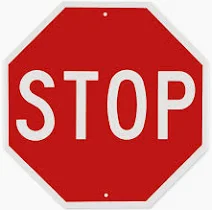

Below we give a possible solution. Don't let us spoil your fun.

In [ ]:
def mse_loss(model, s, a):
    return ((model(s) - a) ** 2).mean()


print(f"loss of an untrained network: {mse_loss(BCPolicy(H), states[:1024], chunks[:1024]).item():.3f}")

In [ ]:
torch.manual_seed(0)
bc = BCPolicy(H)
bc_losses = train(bc, mse_loss, states, chunks)

In [ ]:
#@title Helper: rollouts, success, floor and ceiling { display-mode: "form" }
T_MAX = 60  # control steps per episode (the demonstrations take about 26)


def rollout(policy, starts, n_steps=T_MAX):
    """Run the policy from every start configuration for n_steps steps, executing every chunk in full before asking
    for the next. Kinematic: the arm is placed where the policy says. Returns the joint trajectories, (N, n_steps + 1, 6)."""
    q = np.array(starts, dtype=float)
    trajectory = [q.copy()]
    while len(trajectory) <= n_steps:
        chunk = policy(q) * A_SCALE  # (N, H, 6) displacements in radians
        for k in range(chunk.shape[1]):
            q = q + chunk[:, k]
            trajectory.append(q.copy())
            if len(trajectory) > n_steps:
                break
    return np.stack(trajectory, axis=1)


def bc_policy(q, model=None):
    with torch.no_grad():
        return (model or bc)(torch.tensor(q, dtype=torch.float32)).reshape(len(q), -1, 6).numpy()


def touching():
    """The name of the first thing (other than itself) the robot touches right now, or None."""
    for i in range(data.ncon):
        contact = data.contact[i]
        for geom in (contact.geom1, contact.geom2):
            name = model.geom(geom).name
            if not body_of_geom(geom).startswith(("robot_", "tool_")):
                return name or body_of_geom(geom)
    return None


def evaluate(trajectories):
    """Follow joint trajectories (N, T + 1, 6) in MuJoCo. Returns a dict with the tip paths (N, T + 1, 3), the step of
    the first collision and of reaching the goal (T + 1 if never), what was hit, success (goal before any collision),
    and the side each successful rollout took ("middle" for a rollout that hit the post, "other" for any other failure)."""
    current = get_configuration()
    n, steps = trajectories.shape[:2]
    tips = np.zeros((n, steps, 3))
    hit, reached = np.full(n, steps), np.full(n, steps)
    hit_what = [None] * n
    for i, trajectory in enumerate(trajectories):
        for t, q in enumerate(trajectory):
            set_configuration(q)
            tips[i, t] = get_tcp_position()
            if hit[i] == steps and robot_in_collision():
                hit[i], hit_what[i] = t, touching()
            if reached[i] == steps and np.linalg.norm(tips[i, t] - GOAL_XYZ) < GOAL_EPS:
                reached[i] = t
    set_configuration(current)
    success = reached < hit
    side = np.array([side_of(tips[i, :reached[i] + 1]) if success[i] else ("middle" if hit_what[i] == "post" else "other")
                     for i in range(n)])
    return {"tips": tips, "hit": hit, "reached": reached, "hit_what": hit_what, "success": success, "side": side,
            "trajectories": trajectories}


test_starts = sample_starts(200, seed=12345)  # held-out start configurations, never seen in training
bc_eval = evaluate(rollout(bc_policy, test_starts))
print(f"BC: {bc_eval['success'].mean():.0%} of 200 rollouts reach the goal without touching anything")


def random_policy(q):
    """The floor: chunks drawn at random from the demonstrations, regardless of where the arm is."""
    return chunks[torch.randint(len(chunks), (len(q),))].reshape(len(q), -1, 6).numpy()


def pad(path, n_steps=T_MAX):
    """A planner path as a trajectory of n_steps + 1 configurations (it stays at its end)."""
    extra = max(0, n_steps + 1 - len(path))
    return np.concatenate([path, np.repeat(path[-1:], extra, axis=0)])[:n_steps + 1]


def planner_trajectory(q0):
    path = None
    while path is None:
        path = demonstrate_tip_path(tip_path([q0])[0, :2], q0)
    return pad(path)


def wilson_interval(k, n, z=1.96):
    p = k / n
    center = (p + z ** 2 / (2 * n)) / (1 + z ** 2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / (1 + z ** 2 / n)
    return center - half, center + half


EVALS = {}  # method -> evaluation


def report(name, evaluation):
    EVALS[name] = evaluation
    success = evaluation["success"]
    low, high = wilson_interval(success.sum(), len(success))
    sides = {s: np.mean(evaluation["side"] == s) for s in ("left", "right", "middle", "other")}
    print(f"{name + ':':9s} {success.mean():4.0%}   (95% CI {low:.0%}-{high:.0%}, n={len(success)})   "
          f"left {sides['left']:.0%}, right {sides['right']:.0%}, into the post {sides['middle']:.0%}, other failures {sides['other']:.0%}")


set_seed(0)
report("floor", evaluate(rollout(random_policy, test_starts)))
report("BC (MSE)", bc_eval)
report("planner", evaluate(np.stack([planner_trajectory(q0) for q0 in test_starts])))

METHOD_COLORS = {"floor": "#8a8a8a", "BC (MSE)": "#d0702a", "flow": "#5b4bc4", "planner": "#1f9a62", "Diffuser": "#4a3c9c"}
ROUTE_COLORS = {"left": SIDE_COLORS["left"], "right": SIDE_COLORS["right"], "middle": "#d62728", "other": "#999999"}


def plot_success(evals, ax):
    order = ["floor", "BC (MSE)", "flow", "Diffuser", "planner"]  # floor, the policies, the ceiling
    names = [n for n in order if n in evals] + [n for n in evals if n not in order]
    rates = [evals[n]["success"].mean() for n in names]
    errors = np.array([wilson_interval(evals[n]["success"].sum(), len(evals[n]["success"])) for n in names]).T
    ax.bar(names, rates, color=[METHOD_COLORS.get(n, "0.5") for n in names],
           yerr=np.abs(errors - np.array(rates)), capsize=4)
    for i, (r, high) in enumerate(zip(rates, errors[1])):
        ax.text(i, high + 0.025, f"{r:.0%}", ha="center")
    ax.set_ylim(0, 1.15)
    ax.set_ylabel("goal reached, nothing touched")
    ax.set_title(f"success on {len(next(iter(evals.values()))['success'])} held-out starts")


def plot_rollouts(ax, evaluation, title, n_shown=60):
    """Tip paths from above, coloured by route: left (blue) or right (orange) of the post, into the post (red), other failure (grey)."""
    draw_top_view(ax, title)
    for tips, side, hit in list(zip(evaluation["tips"], evaluation["side"], evaluation["hit"]))[:n_shown]:
        ax.plot(tips[:hit + 1, 0], tips[:hit + 1, 1], color=ROUTE_COLORS[side], alpha=0.6, linewidth=1)
        if hit <= T_MAX:
            ax.plot(tips[hit, 0], tips[hit, 1], "x", color=ROUTE_COLORS["middle"], markersize=4)


def print_failures(name, evaluation):
    failed = ~evaluation["success"]
    what = {}
    for f, w, r in zip(failed, evaluation["hit_what"], evaluation["reached"]):
        if f:
            key = f"hit {w}" if w else "never reached the goal"
            what[key] = what.get(key, 0) + 1
    print(f"{name}: {failed.sum()} failures of {len(failed)}: " + ", ".join(f"{k} {v}" for k, v in sorted(what.items(), key=lambda kv: -kv[1])))


def fork_figure(evals=None):
    """The figure of this part: the demonstrations, the BC and flow rollouts, and the success of every method."""
    evals = evals or EVALS
    fig, axes = plt.subplots(2, 2, figsize=(10, 9.2))
    draw_top_view(axes[0, 0], f"{len(demos)} demonstrations of the planner")
    draw_tip_paths(axes[0, 0], demo_tips, [SIDE_COLORS[s] for s in demo_sides], alpha=0.35)
    if "BC (MSE)" in evals:
        plot_rollouts(axes[0, 1], evals["BC (MSE)"], f"behaviour cloning: {evals['BC (MSE)']['success'].mean():.0%} succeed")
    if "flow" in evals:
        plot_rollouts(axes[1, 0], evals["flow"], f"flow matching: {evals['flow']['success'].mean():.0%} succeed")
    plot_success(evals, axes[1, 1])
    plt.tight_layout()
    return fig


def fork_numbers(evals=None):
    """The numbers behind the figure, for the JSON next to it."""
    evals = evals or EVALS
    out = {"n_demos": len(demos), "n_left": int(np.sum(demo_sides == "left")), "n_right": int(np.sum(demo_sides == "right")),
           "n_starts": len(test_starts), "train_steps": TRAIN_STEPS, "horizon": H,
           "definitions": {"collision_free": "no contact within T_MAX steps", "reached_goal": "tip within GOAL_EPS of the goal before any contact (success)",
                           "left": "passed between the post and the robot", "right": "passed on the far side of the post",
                           "middle": "touched the post", "other": "touched something else or never reached the goal"}}
    key = {"floor": "random", "BC (MSE)": "bc", "flow": "flow", "planner": "planner", "Diffuser": "diffuser"}
    for name, ev in evals.items():
        entry = {"collision_free": float(np.mean(ev["hit"] > T_MAX)), "reached_goal": float(ev["success"].mean())}
        for s in ("left", "right", "middle", "other"):
            entry[s] = float(np.mean(ev["side"] == s))
        out[key.get(name, name)] = entry
    return out


def save_fork_figure(stem, evals=None):
    """fig-fork-ur5e.{png,svg,json} at the given path stem (the deck and the website read these)."""
    import json as _json
    fig = fork_figure(evals)
    fig.savefig(stem + ".png", dpi=200)
    fig.savefig(stem + ".svg")
    plt.close(fig)
    _json.dump(fork_numbers(evals), open(stem + ".json", "w"), indent=1)


FORK_START = int(np.argmax(bc_eval["side"] == "middle")) if (bc_eval["side"] == "middle").any() else 0  # a start where BC fails

if LIVE:
    fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
    plot_success(EVALS, axes[0])
    plot_rollouts(axes[1], bc_eval, "BC (MSE) rollouts (the first 60), seen from above")
    plt.show()
    print_failures("BC (MSE)", bc_eval)
    k = FORK_START
    bc_clip = arm_frames(bc_eval["trajectories"][k][:bc_eval["hit"][k] + 1])
    bc_clip += tint(bc_clip[-1:]) * 6  # a red flash where it touched the post
    planner_clip = arm_frames(EVALS["planner"]["trajectories"][k][:EVALS["planner"]["reached"][k] + 1])
    media.show_video(side_by_side(label_frames(bc_clip, f"BC from held-out start {k}: into the post"),
                                  label_frames(planner_clip, "the planner from the same start")),
                     fps=10, title="the same start, cloned policy and planner")

The minimizer of $\mathbb{E}\|\pi(s) - a\|^2$ is the **conditional mean** $\mathbb{E}[a \mid s]$. In the start region
the demonstrations disagree: from almost the same joint angles, some swing the shoulder one way to pass between the post
and the robot, the others the other way to pass on the far side. Their mean swings neither way: it heads for the post.
Each of the two answers is right, and their average is wrong: 25% of the cloned policy's rollouts end
against the post, and 75% reach the goal (the planner: 100%; chunks drawn at random
from the demonstrations: 10%).

The successful BC rollouts are not a contradiction: with Fourier features the network is flexible enough to partly
*memorize* which way the nearest few demonstrations went, so from many starts it commits to one side. Between starts
whose neighbours disagree, it averages, and fails. A smoother network averages more (try it: feed `BCPolicy` the raw
joint angles instead of their Fourier features), so this is a fair, strong version of BC. What we need is a policy that
can represent "either this or that", not the average of both.

## A flow-matching policy

Instead of predicting *the* action chunk, a generative policy learns the whole conditional distribution $p(a \mid s)$, and **samples** from it. **Flow matching**, the idea behind a VLA's action expert (Part 2), learns a **velocity field** that transports simple noise into data. Concretely, with $x_0 \sim \mathcal{N}(0, I)$ a noise vector and $x_1 = a$ a demonstrated chunk (both in $\mathbb{R}^{6H}$), take the straight line between them,

$$x_t = (1 - t)\, x_0 + t\, x_1, \qquad t \in [0, 1],$$

whose velocity is $\frac{d x_t}{dt} = x_1 - x_0$. A network $v_\theta(x_t, t, s)$ is trained to predict this velocity from the point $x_t$, the time $t$ and the observation $s$:

$$\mathcal{L}_{\text{FM}}(\theta) = \mathbb{E}_{(s, x_1),\, x_0,\, t \sim U[0,1]} \left\| v_\theta(x_t, t, s) - (x_1 - x_0) \right\|^2 .$$

This is still a squared error, and its minimizer is still an average: the average velocity of all the straight lines that pass through $x_t$ at time $t$. The difference is *where* we average. Early on ($t \approx 0$) many lines pass through every point and the velocity is a blend, but as $t$ grows the lines that pass through a point all lead to the same mode, and the field splits. Following the *exact* field from a random $x_0$ would land on one mode or the other. Our network only approximates the field, from finite data and a finite budget, and we will see where the approximation shows.

The network is the same MLP as before, with two more inputs: the noisy chunk $x_t$ and the time $t$ (also through Fourier features).

In [ ]:
class FlowPolicy(nn.Module):
    def __init__(self, horizon):
        super().__init__()
        self.horizon = horizon
        self.net = mlp(6 * horizon + T_FEATURES + S_FEATURES, 6 * horizon)

    def forward(self, x, t, s):
        """The velocity at the noisy chunk x (B, 6H), time t (B, 1), given the joint state s (B, 6)."""
        return self.net(torch.cat([x, fourier_features(t, T_FREQUENCIES), fourier_features(s, S_FREQUENCIES)], dim=-1))

⚒ **Task 2**: Write the flow-matching loss. For a minibatch of joint states `s` (shape `(B, 6)`) and chunks `a` (shape
`(B, 6H)`): draw the noise $x_0$ (`torch.randn_like`), one time $t$ per example (`torch.rand`, shape `(B, 1)`), form
$x_t$, and return the mean squared difference between `model(x_t, t, s)` and $x_1 - x_0$.

The cell evaluates your loss on a batch with an untrained network.

In [ ]:
def flow_matching_loss(model, s, a):
    return torch.zeros((), requires_grad=True)  # your code here


torch.manual_seed(0)
flow = FlowPolicy(H)
untrained_loss = flow_matching_loss(flow, states[:1024], chunks[:1024]).item()
print(f"flow-matching loss of the untrained network: {untrained_loss:.3f}")

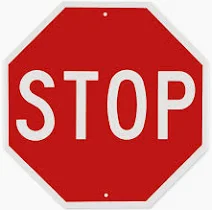

Below we give a possible solution. Don't let us spoil your fun.

In [ ]:
def flow_matching_loss(model, s, a):
    x1 = a
    x0 = torch.randn_like(x1)  # noise
    t = torch.rand(len(x1), 1)  # one time per example
    x_t = (1 - t) * x0 + t * x1  # a point on the straight line from noise to data
    return ((model(x_t, t, s) - (x1 - x0)) ** 2).mean()  # regress the velocity of that line


torch.manual_seed(0)
flow = FlowPolicy(H)
untrained_loss = flow_matching_loss(flow, states[:1024], chunks[:1024]).item()
print(f"flow-matching loss of the untrained network: {untrained_loss:.3f}")

In [ ]:
flow_losses = train(flow, flow_matching_loss, states, chunks)

The loss trained a velocity field $v_\theta(x, t, s)$. To **act**, we integrate it from noise to an action chunk. With
$N$ Euler steps, starting from $x_0 \sim \mathcal{N}(0, I)$ and $t_k = k / N$:

$$x_{k+1} = x_k + \frac{1}{N}\, v_\theta(x_k, t_k, s), \qquad k = 0, \dots, N - 1,$$

and $x_N$ is the chunk. We use $N = 10$.

⚒ **Task 3**: Write `sample_chunks(model, s, n_steps=10)`: for a batch of joint states `s` (shape `(B, 6)`), draw the
noise, take the $N$ Euler steps along `model(x, t, s)` (`t` of shape `(B, 1)`), and return the chunks reshaped to
`(B, horizon, 6)`. `flow_policy` wraps it for the rollouts. The cell checks the shape; the plot after the solution
shows 300 sampled chunks from one start.

In [ ]:
@torch.no_grad()
def sample_chunks(model, s, n_steps=10):
    """Sample one action chunk per joint state in s (B, 6) by Euler integration. Returns (B, horizon, 6)."""
    x = torch.randn(len(s), 6 * model.horizon)  # x_0: noise
    return x.reshape(len(s), model.horizon, 6)  # your code here: integrate before reshaping


def flow_policy(q, n_steps=10, model=None):
    with torch.no_grad():
        return sample_chunks(model or flow, torch.tensor(q, dtype=torch.float32), n_steps).numpy()


print("one chunk per start:", flow_policy(test_starts[:4]).shape)

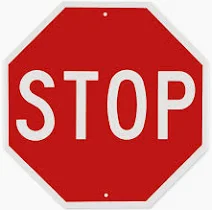

Below we give a possible solution. Don't let us spoil your fun.

In [ ]:
@torch.no_grad()
def sample_chunks(model, s, n_steps=10):
    """Sample one action chunk per joint state in s (B, 6) by Euler integration. Returns (B, horizon, 6)."""
    x = torch.randn(len(s), 6 * model.horizon)  # x_0: noise
    for k in range(n_steps):
        t = torch.full((len(s), 1), k / n_steps)
        x = x + model(x, t, s) / n_steps  # one Euler step along the learned velocity field
    return x.reshape(len(s), model.horizon, 6)


def flow_policy(q, n_steps=10, model=None):
    with torch.no_grad():
        return sample_chunks(model or flow, torch.tensor(q, dtype=torch.float32), n_steps).numpy()


print("one chunk per start:", flow_policy(test_starts[:4]).shape)

In [ ]:
def plot_chunks(ax, q0, chunks_, color, title, alpha=0.3):
    """Draw each action chunk as the path the tip makes from the configuration q0."""
    draw_top_view(ax, title)
    ax.set_xlim(0.35, 0.8)
    ax.set_ylim(-0.05, 0.3)
    for chunk in chunks_:
        xyz = tip_path(q0 + np.concatenate([[np.zeros(6)], np.cumsum(chunk * A_SCALE, axis=0)]))
        ax.plot(xyz[:, 0], xyz[:, 1], color=color, alpha=alpha, linewidth=1)
    ax.plot(*tip_path([q0])[0, :2], "ks", markersize=6)


torch.manual_seed(0)
probe = test_starts[:1]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
plot_chunks(axes[0], probe[0], bc_policy(probe), METHOD_COLORS["BC (MSE)"], "BC: one chunk", alpha=1)
plot_chunks(axes[1], probe[0], flow_policy(np.repeat(probe, 300, axis=0)), METHOD_COLORS["flow"], "flow: 300 sampled chunks")
plt.show()

In [ ]:
torch.manual_seed(0)
flow_eval = evaluate(rollout(flow_policy, test_starts))
report("flow", flow_eval)

fig = fork_figure()
plt.show()

for name in ("BC (MSE)", "flow"):
    print_failures(name, EVALS[name])

In [ ]:
torch.manual_seed(1)
same_start = np.repeat(test_starts[FORK_START:FORK_START + 1], 16, axis=0)  # the start of the BC video above, 16 times
samples_eval = evaluate(rollout(flow_policy, same_start))
counts = {side: int(np.sum(samples_eval["side"] == side)) for side in ("left", "right", "middle")}
print(f"16 samples of the flow policy from the same start: {counts['left']} left of the post, {counts['right']} right, {counts['middle']} into it")
clips = []
for side in ("left", "right"):
    if counts[side]:
        i = int(np.argmax(samples_eval["side"] == side))
        clips.append(label_frames(arm_frames(samples_eval["trajectories"][i][:samples_eval["reached"][i] + 1]), f"flow matching, sample {i}: {side} of the post"))
media.show_video(side_by_side(*clips), fps=10, title="two samples, same start, different noise")

The flow-matching policy succeeds 87% of the time, against 75% for BC and
100% for the planner, with the same network, the same data and the same training budget; only the
loss and the way we read out an action changed. Both routes survive: 42% of its successful rollouts
pass between the post and the robot, close to the 43% of the demonstrations. Each rollout commits to
one route and keeps it, because every new chunk is sampled from a configuration that is already on one route, where
the data has only one mode.

It is not perfect: close to the fork, a sampled chunk can still land between the modes where the learned field is
inaccurate, and small errors add up against a 5 cm margin. The failures are listed above the figure.

❓ **What did we pay for this?** Count the network evaluations per action chunk, for BC and for our sampler.

---

**Stop 1** — slides. The live cell is the rollout plot of the cloned policy (after Task 1).

---

## ★ Whole trajectories at once: a learned RRT

Our policies decide 8 steps at a time, and look again. A motion planner works differently: RRT returns the **whole path**
from start to goal in one go. Can a generative model do that too? **Diffuser** ([Janner et al., 2022](https://arxiv.org/abs/2205.09991))
does exactly this: it treats an entire trajectory as *one* sample of a generative model, and generates it from noise.
Ours is the smallest version of the idea: a path of 12 joint configurations from start to goal (like the simplified path
that RRT returns), 72 numbers, generated by Part 1's flow matching; the robot then follows it step by step.

How do we tell it where to start? Not by conditioning, but by **inpainting**: at every step of the sampler we overwrite
the first configuration with the start (as noisy as the rest of the trajectory is at that moment), and let the model fill
in the remaining 11 so that they fit. The goal is fixed in this problem, so the model learns it from the data.

In [ ]:
L = 12  # every path: 12 joint configurations from start to goal, like a simplified RRT path


def fixed_length(path, n=L):
    """n configurations evenly spaced (by distance travelled in joint space) along a joint path."""
    arc = np.concatenate([[0.0], np.cumsum(np.linalg.norm(np.diff(path, axis=0), axis=1))])
    s = np.linspace(0, arc[-1], n)
    return np.stack([np.interp(s, arc, path[:, k]) for k in range(path.shape[1])], axis=1)


trajectories = torch.tensor(np.stack([fixed_length(p) for p in demos]), dtype=torch.float32)  # (300, 12, 6)
Q_MEAN, Q_STD = trajectories.reshape(-1, 6).mean(0), trajectories.reshape(-1, 6).std(0) + 1e-3  # the model works in normalized joint angles


class TrajectoryFlow(nn.Module):
    """A velocity field over whole paths: v(x_t, t), with x_t a noisy path of L configurations flattened to 6L numbers."""

    def __init__(self, hidden=512):
        super().__init__()
        self.net = mlp(6 * L + T_FEATURES, 6 * L, hidden)

    def forward(self, x_t, t):
        return self.net(torch.cat([x_t, fourier_features(t, T_FREQUENCIES)], dim=1))


def trajectory_flow_loss(model, x_1):
    """Part 1's flow-matching loss, with a whole trajectory as the sample (and no observation to condition on)."""
    x_1 = ((x_1 - Q_MEAN) / Q_STD).reshape(len(x_1), -1)
    x_0 = torch.randn_like(x_1)
    t = torch.rand(len(x_1), 1)
    return ((model((1 - t) * x_0 + t * x_1, t) - (x_1 - x_0)) ** 2).mean()


@torch.no_grad()
def sample_trajectories(model, starts, n_steps=32):
    """One trajectory per start configuration, generated from noise, with the start inpainted at every step."""
    starts = (torch.as_tensor(np.asarray(starts), dtype=torch.float32) - Q_MEAN) / Q_STD
    x_0 = torch.randn(len(starts), L, 6)
    x = x_0.clone()
    for k in range(n_steps):
        t = k / n_steps
        x[:, 0] = (1 - t) * x_0[:, 0] + t * starts  # the first configuration, exactly as noisy as the rest at time t
        x = x + model(x.reshape(len(x), -1), torch.full((len(x), 1), t)).reshape(x.shape) / n_steps
    x[:, 0] = starts
    return (x * Q_STD + Q_MEAN).numpy()


def follow(waypoints, step=A_SCALE):
    """The joint path through the waypoints, one configuration every `step` radians (the robot follows it step by step)."""
    return resample(waypoints, step)


set_seed(0)
diffuser = TrajectoryFlow()
start_time = time.time()
diffuser_losses = train(diffuser, lambda model, s, a: trajectory_flow_loss(model, a), trajectories[:, 0], trajectories, n_steps=TRAIN_STEPS)

# 30 trajectories from one start, and one from each of the 200 held-out starts
one_start = np.repeat(test_starts[:1], 30, axis=0)
samples = sample_trajectories(diffuser, one_start)
diffuser_eval = evaluate(np.stack([pad(follow(t)) for t in sample_trajectories(diffuser, test_starts)]))
report("Diffuser", diffuser_eval)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
draw_top_view(axes[0], "30 trajectories from one start (no collision checker)")
for t in samples:
    xyz = tip_path(t)
    axes[0].plot(xyz[:, 0], xyz[:, 1], "o-", color=METHOD_COLORS["Diffuser"], alpha=0.5, linewidth=1, markersize=2)
axes[0].plot(*tip_path(test_starts[:1])[0, :2], "ko")
plot_rollouts(axes[1], diffuser_eval, f"one trajectory from each held-out start: {diffuser_eval['success'].mean():.0%} succeed")
plt.tight_layout()
plt.show()

Look at the samples from one start: some pass the post on the robot's side, some on the far side, all from the same
configuration, exactly like the planner's demonstrations. No collision checker was used to produce them; the model
learned where the free space is from 300 paths. Now and then a sample cuts *between* the two routes, into the post:
BC's failure, much rarer, because a generative model only lands between its modes when its learned field is inaccurate
there.

❓ **RRT and Diffuser both draw samples. Where does each get its correctness from? Which would you use in a world it has
never seen (move the post), and which when collision checking is very expensive?**

# Part 2 — See and act: a vision-language-action model

In Part 1 we learned one piece, the motion planner, and the learned piece still had a hand-made model around it: the
scene that MuJoCo and the IK know, and the planner that made its demonstrations. Now we go all the way.

A **vision-language-action model** (VLA) replaces the whole stack of tutorials 1.2 to 4.1 by one network: camera images and
an instruction in English go in, joint targets come out, ten times per second. No PDDL, no IK, no RRT, no state
estimator. Ours is [**SmolVLA**](https://huggingface.co/papers/2506.01844) (Hugging Face, 2025), small enough to run on
a T4: 450 million parameters, in two parts:

* a **vision-language model** (SmolVLM2), itself in two parts: **SigLIP**, the vision encoder (the eye), cuts each
  camera image into patches and turns them into tokens; it was trained on web image-caption pairs, so its tokens
  already carry meaning. **SmolLM2**, the language model, cut to its first 16 layers, reads those image tokens next to
  the words of the instruction. (The same split as $\pi_0$'s PaliGemma, SigLIP + Gemma, smaller.)
* an **action expert**, a smaller transformer that turns what the VLM understood into a **chunk** of 50 actions, with
  **flow matching**: the very same idea as Part 1's `FlowPolicy`, at a larger scale.

It was pretrained on about 23,000 recordings of cheap robot arms, made by the community. It has never seen a UR5e, a
suction cup, or our blocks.

## Demonstrations from tutorial 4.1

Where do the demonstrations come from? From **tutorial 4.1's skills**, unchanged: `pick_up` and `stack`, with their IK,
their RRT-Connect paths and their servo targets. We put three blocks of different colours at random places on table
`t2`, pick two of them and an instruction ("put the red block on the blue block"), let the skills carry it out, and
record what a learned policy would see and do, 10 times per second:

* **three images**: a camera on the wrist, which moves with the hand, and two that watch the table from the front and
  from the side (tutorial 4.1's cameras see the whole room, and a block would be smaller than one patch; more on patches
  below),
* the **state**: the 6 joint angles and whether the suction is on,
* the **action**: the 6 joint targets that the skill sent to the servos, and whether the suction should be on.

Two more details, and they turned out to matter more than anything else (see the box below): every demonstration
starts from a **random pose** of the arm, and during the planned transit motions the servos get the skill's target
plus a small, slowly drifting **random offset** that the skill keeps correcting, while the recorder keeps the clean
target as the label (*noise injection*, [Laskey et al., 2017](https://arxiv.org/abs/1703.09327)).

We did this 900 times (about 60 minutes on a laptop) and fine-tuned SmolVLA on the result for
20,000 steps on one GPU, which took 5.4 hours. The collapsed cells below rebuild tutorial 4.1's world
and skills, unchanged, and then add the cameras, the random tasks and the recorder.

> **Our first attempt failed, and how.** We first recorded 300 demonstrations that all started from the same home pose,
> without noise, and fine-tuned on them overnight. Offline, the policy was nearly perfect: given a frame of a
> demonstration it never saw, it predicted the demonstrator's next actions to within about 0.01 rad. On the robot, it
> succeeded on **none** of the tasks. It moved, smoothly, and never turned towards the block.
>
> The reason is a shortcut called **copycat**. Every motion started at the same pose and went in a straight line, so
> once the arm had started to turn, its own joint angles told the policy which way to keep going: it never had to look
> at the cameras, except at the very first step, which is one frame in a hundred and easy to get wrong. Offline, the
> demonstrations make that first step for it; on its own, it never commits. Random starting poses take the shortcut
> away, and the noise shows the policy states slightly off the path and how the skill comes back from them, which is
> where a learned policy finds itself as soon as it acts on its own (the *distribution shift* of behaviour cloning).
>
> ❓ **Why can an offline error of 0.01 rad say nothing about how a policy behaves closed loop?**

In [ ]:
#@title Helper: three cameras, random scenes, and a recorder { display-mode: "form" }
# New in this tutorial. Everything above this cell is tutorial 4.1, unchanged.

# --- a camera on the wrist, looking down past the suction cup ---
TOOL_XML = """
<mujoco model="suction_gripper">
  <worldbody>
    <body name="suction_cup">
      <geom name="suction_cup" type="cylinder" size="0.02 0.03" pos="0 0 0.03" rgba="0.3 0.3 0.3 1" mass="0.05"/>
      <site name="tcp" pos="0 0 0.06" size="0.005" rgba="1 0 0 1"/>
      <camera name="wrist" pos="0 0.09 -0.01" xyaxes="-1 0 0 0 0.8 0.6" fovy="75"/>
    </body>
  </worldbody>
</mujoco>
"""

# --- two more cameras, close to table t2 where the blocks are (tutorial 4.1's cameras see the whole room, and a block
# would be smaller than a single patch of the images the policy sees) ---
SCENE_XML = SCENE_XML.replace("</worldbody>", """
    <camera name="t2_front" pos="1.25 0 1.25" xyaxes="0 1 0 -0.632 0 0.775" fovy="55"/>
    <camera name="t2_side" pos="0.62 -0.75 1.2" xyaxes="1 0 0 0 0.539 0.842" fovy="55"/>
  </worldbody>""")

CAMERAS = ["wrist", "front", "side"]  # what the learned policy sees: one view that moves with the hand, two that don't
MUJOCO_CAMERA = {"wrist": "tool_wrist", "front": "t2_front", "side": "t2_side"}  # the tool's names get the prefix "tool_"
IMAGE_SIZE = 256  # SmolVLA was pretrained on three 256x256 views
FPS = 10  # the policy acts 10 times per second: every 50 steps of the 2 ms simulation
STEPS_PER_FRAME = round(1 / (FPS * 0.002))
obs_renderer = None
_load_scene_tutorial7 = load_scene


def load_scene(layout=DEFAULT_LAYOUT, window=True):
    """Tutorial 4.1's load_scene, plus a second renderer for the small images the policy sees."""
    global obs_renderer
    _load_scene_tutorial7(layout, window)
    if obs_renderer is not None:
        obs_renderer.close()
    obs_renderer = mujoco.Renderer(model, height=IMAGE_SIZE, width=IMAGE_SIZE)


def observe_images():
    """What the policy sees right now: one IMAGE_SIZE x IMAGE_SIZE RGB image per camera."""
    images = {}
    for camera in CAMERAS:
        obs_renderer.update_scene(data, camera=MUJOCO_CAMERA[camera])
        images[camera] = obs_renderer.render().copy()
    return images


def robot_state():
    """What the policy knows about its own body: 6 joint angles and whether the suction is on (0 or 1)."""
    return np.concatenate([get_configuration(), [float(grasped_block() is not None)]]).astype(np.float32)


# --- random scenes: three blocks of different colors, somewhere on table t2 ---

TASK_TEMPLATES = ["put the {a} block on the {b} block", "stack the {a} block on top of the {b} one",
                  "place the {a} block onto the {b} block"]


def random_layout(rng, n_blocks=3, table="t2"):
    """A layout with n_blocks blocks of distinct colors at random, non-overlapping spots on the table."""
    colors = rng.choice(list(COLORS), size=n_blocks, replace=False)
    center = np.array(TABLES_XY[table])
    spots = []
    while len(spots) < n_blocks:
        xy = center + rng.uniform(-1, 1, size=2) * (0.3 - BLOCK_HALF_WIDTH - 0.02)
        if np.linalg.norm(xy) < MAX_REACH - 0.05 and all(np.max(np.abs(xy - s)) > 2 * BLOCK_HALF_WIDTH + 0.03 for s in spots):
            spots.append(xy)
    surface = 0.72
    return {f"b{i + 1}": (str(color), [xy[0], xy[1], surface + BLOCK_HALF_HEIGHT]) for i, (color, xy) in enumerate(zip(colors, spots))}


TABLES_XY = {"t1": (0.0, -0.65), "t2": (0.65, 0.0), "t3": (0.0, 0.65)}


def random_task(rng):
    """A random scene and an instruction for it: (layout, block to move, block to put it on, instruction)."""
    layout = random_layout(rng)
    a, b = rng.choice(list(layout), size=2, replace=False)
    text = rng.choice(TASK_TEMPLATES).format(a=layout[a][0], b=layout[b][0])
    return layout, str(a), str(b), str(text)


# --- the recorder: tutorial 2.1's move_to and follow_path, with one extra line that records every 50th step ---

recorder = None  # set to a list to record (images, state, joint targets) at FPS frames per second
_sim_steps = 0


def _record(target):
    global _sim_steps
    if recorder is not None and _sim_steps % STEPS_PER_FRAME == 0:
        recorder.append({"images": observe_images(), "state": robot_state(), "target": np.array(target, dtype=np.float32)})
    _sim_steps += 1


def move_to(target, tolerance=0.03, max_steps=2000, render_every=50, camera="overview"):
    frames = []
    for i in range(max_steps):
        _record(target)  # <- new
        data.ctrl[ctrl_idx] = target
        mujoco.mj_step(model, data)
        if i % render_every == 0:
            frames.append(render(camera))
        if np.linalg.norm(get_configuration() - target) < tolerance and np.linalg.norm(get_joint_velocities()) < 0.05:
            return True, frames
    return False, frames


# Noise injection while demonstrating (DART, Laskey et al. 2017): during the planned transit motions, the servos get the
# planner's target plus a slowly drifting random offset, while the recorder keeps the clean target as the label. The
# skill corrects the drift, so the demonstrations show the policy what to do when it is a little off the path, which is
# exactly where a learned policy ends up when it acts on its own.
TRANSIT_NOISE = 0.0  # radians (standard deviation of the offset, per joint); 0 = off. Keep it well below the 0.1 rad at
# which follow_path moves on to the next waypoint, or the robot never "arrives".
_noise = np.zeros(6)


def transit_noise(rng=np.random):
    global _noise
    if TRANSIT_NOISE == 0:
        return 0.0
    keep = 0.998  # at 500 Hz: the offset changes over about half a second
    _noise = keep * _noise + np.sqrt(1 - keep**2) * TRANSIT_NOISE * rng.standard_normal(6)
    return _noise


def follow_path(waypoints, tolerance=0.1, max_steps_per_waypoint=500, render_every=50, camera="overview"):
    frames = []
    step = 0
    for i, target in enumerate(waypoints):
        if i == len(waypoints) - 1:
            success, new_frames = move_to(target, render_every=render_every, camera=camera)
            return success, frames + new_frames
        for _ in range(max_steps_per_waypoint):
            _record(target)  # <- new
            data.ctrl[ctrl_idx] = target + transit_noise()  # <- new (zero unless TRANSIT_NOISE is set)
            mujoco.mj_step(model, data)
            if step % render_every == 0:
                frames.append(render(camera))
            step += 1
            if np.linalg.norm(get_configuration() - target) < tolerance:
                break
        else:
            return False, frames
    return True, frames


load_scene()

In [ ]:
#@title Helper: the demonstrator (tutorial 4.1's skills) and the dataset it writes { display-mode: "form" }

def random_start(rng, max_tries=200):
    """A random collision-free configuration around HOME, with the tool well above the table. Starting every
    demonstration from the same pose lets a policy read the direction of the motion off its own joint angles instead
    of looking at the cameras (the "copycat" shortcut); random starts take that shortcut away."""
    spread = np.array([1.0, 0.35, 0.4, 0.5, 0.2, 1.5])
    for _ in range(max_tries):
        q = HOME + rng.uniform(-1, 1, size=6) * spread
        set_configuration(q)
        if not in_collision(q) and get_tcp_position()[2] > 0.95:
            data.ctrl[ctrl_idx] = q
            data.qvel[:] = 0
            mujoco.mj_forward(model, data)
            return q
    set_configuration(HOME)
    return HOME


def demonstrate(rng, start_randomly=True, noise=0.02):
    """One demonstration: a random scene, an instruction, and tutorial 4.1's skills carrying it out while we record.

    The arm starts from a random pose (start_randomly) and its transit motions are perturbed by `noise` radians,
    which the skills correct (see TRANSIT_NOISE). Returns (frames, info). frames is a list of dicts with the three
    images, the state and the action at each recorded step; info says what the task was and whether it succeeded.
    """
    global recorder, _sim_steps, TRANSIT_NOISE, _noise
    layout, a, b, text = random_task(rng)
    load_scene(layout)
    start = random_start(rng) if start_randomly else HOME
    set_seed(int(rng.integers(2**31)))
    TRANSIT_NOISE, _noise = noise, np.zeros(6)
    recorder, _sim_steps = [], 0  # record from the first step of this episode
    ok = pick_up(a)[0] and stack(a, b)[0] and go_to(HOME)[0]
    frames, recorder = recorder, None
    TRANSIT_NOISE = 0.0
    success = ok and ("on", a, b) in estimate_state()
    # the action at step t: the joint targets the servos were given, and whether the suction is on at step t+1
    # (so that "switch the suction on" comes before the state that shows it on, as a command should)
    suction = [f["state"][6] for f in frames[1:]] + [frames[-1]["state"][6]]
    for f, s in zip(frames, suction):
        f["action"] = np.concatenate([f.pop("target"), [s]]).astype(np.float32)
    return frames, {"layout": layout, "move": a, "onto": b, "task": text, "success": bool(success), "n_frames": len(frames),
                    "start": [round(float(x), 4) for x in start], "noise": noise}


STATE_NAMES = [*ROBOT_JOINTS, "suction"]


def dataset_features():
    """The columns of our LeRobot dataset."""
    features = {f"observation.images.{camera}": {"dtype": "video", "shape": (IMAGE_SIZE, IMAGE_SIZE, 3),
                                                 "names": ["height", "width", "channels"]} for camera in CAMERAS}
    features["observation.state"] = {"dtype": "float32", "shape": (7,), "names": STATE_NAMES}
    features["action"] = {"dtype": "float32", "shape": (7,), "names": STATE_NAMES}
    return features


def add_episode(dataset, frames, task):
    for f in frames:
        frame = {f"observation.images.{camera}": f["images"][camera] for camera in CAMERAS}
        frame["observation.state"] = f["state"]
        frame["action"] = f["action"]
        frame["task"] = task
        dataset.add_frame(frame)
    dataset.save_episode()

Here is one demonstration, as the policy will see it (the three cameras side by side), with its instruction:

In [ ]:
import numpy as np

frames, info = demonstrate(np.random.default_rng([0, 7]))  # the 8th demonstration of our dataset, recomputed
print(info["task"], "-", "success" if info["success"] else "failure", "-", len(frames), "steps of 0.1 s")
show_video([np.concatenate([f["images"][c] for c in CAMERAS], axis=1) for f in frames], fps=10)

❓ **The action at step $t$ says whether the suction should be on at step $t+1$, not whether it is on at step $t$. Why
does that matter? What would a policy trained on the other convention learn to do with the suction?**

## The fine-tuned policy at work

In [ ]:
#@title Helper: load a SmolVLA policy and let it drive the robot { display-mode: "form" }
import time

from lerobot.policies.factory import make_pre_post_processors
from lerobot.policies.smolvla.modeling_smolvla import SmolVLAPolicy


# SmolVLA was pretrained with three cameras called camera1, camera2, camera3; we tell it which of ours is which
RENAME_MAP = {"observation.images.front": "observation.images.camera1", "observation.images.wrist": "observation.images.camera2",
              "observation.images.side": "observation.images.camera3"}


def load_policy(path, actions_per_chunk=10):
    """A SmolVLA policy with its input and output processing (renaming, tokenizing, normalizing), on DEVICE.

    The policy predicts 50 actions (5 seconds) at a time; we execute the first actions_per_chunk of them and then
    ask again, looking at the world anew.
    """
    policy = SmolVLAPolicy.from_pretrained(path).to(DEVICE)
    policy.config.n_action_steps = actions_per_chunk
    policy.eval()
    if DTYPE != torch.float32:  # weights stay float32; the GPU computes in DTYPE (autocast), actions come back float32
        for name in ("select_action", "predict_action_chunk"):
            method = getattr(policy, name)
            def in_dtype(*args, _method=method, **kwargs):
                with torch.autocast(device_type="cuda", dtype=DTYPE):
                    return _method(*args, **kwargs).float()
            setattr(policy, name, in_dtype)
    preprocess, postprocess = make_pre_post_processors(policy.config, pretrained_path=path,
                                                       preprocessor_overrides={"device_processor": {"device": DEVICE}})
    return policy, preprocess, postprocess


def policy_input(task):
    """The current observation, in the form the policy's preprocessor expects."""
    images = observe_images()
    batch = {f"observation.images.{c}": torch.from_numpy(images[c]).permute(2, 0, 1).float() / 255 for c in CAMERAS}
    batch["observation.state"] = torch.from_numpy(robot_state())
    batch["task"] = task
    return batch


def apply_action(action):
    """Hold the joint targets for one policy step (0.1 s) and switch the suction on or off as commanded."""
    held = grasped_block()
    if action[6] > 0.5 and held is None:
        grasp()
    elif action[6] <= 0.5 and held is not None:
        release()
    for _ in range(STEPS_PER_FRAME):
        data.ctrl[ctrl_idx] = action[:6]
        mujoco.mj_step(model, data)


@torch.no_grad()
def run_policy(policy, preprocess, postprocess, task, max_seconds=25, camera="t2_front", render_every=2):
    """Let the policy act until max_seconds of robot time have passed. Returns (frames, seconds of computation per chunk).

    camera is a MuJoCo camera name, or a list of them; then frames is a dict: camera -> its frames.
    """
    policy.reset()
    cameras = [camera] if isinstance(camera, str) else list(camera)
    videos, chunk_times = {c: [] for c in cameras}, []
    for step in range(int(max_seconds * FPS)):
        start = time.time()
        new_chunk = len(policy._queues["action"]) == 0 if hasattr(policy, "_queues") and "action" in policy._queues else True
        action = postprocess(policy.select_action(preprocess(policy_input(task))))
        if new_chunk:
            chunk_times.append(time.time() - start)
        apply_action(action.squeeze(0).float().cpu().numpy())
        if step % render_every == 0:
            for c in cameras:
                videos[c].append(render(c))
    return (videos[camera] if isinstance(camera, str) else videos), chunk_times


def evaluate(policy, preprocess, postprocess, seeds, max_seconds=25, video_cameras=None):
    """Success rate of the policy on the random tasks with the given seeds (and the per-task outcomes).

    With video_cameras (a list of MuJoCo camera names), every outcome also carries its videos: camera -> frames.
    """
    outcomes = []
    for seed in seeds:
        layout, a, b, text = random_task(np.random.default_rng([1, seed]))  # [1, seed]: never one of the demonstrations ([0, i])
        load_scene(layout)
        videos, _ = run_policy(policy, preprocess, postprocess, text, max_seconds, camera=video_cameras or [],
                               render_every=2 if video_cameras else 10**9)
        release()
        outcomes.append({"seed": seed, "task": text, "success": ("on", a, b) in estimate_state()})
        if video_cameras:
            outcomes[-1]["videos"] = videos
    return np.mean([o["success"] for o in outcomes]), outcomes

In [ ]:
policy, preprocess, postprocess = load_policy(f"{DATA_DIR}/smolvla-stack/pretrained_model")
print(f"{sum(p.numel() for p in policy.parameters()) / 1e6:.0f}M parameters on {DEVICE}")

A policy acts in **closed loop**: ten times per second it reads the cameras and the joint angles, and the robot moves a
little. The helper above gave you the pieces: `policy_input(task)` reads the three cameras and the state into a
dictionary, `preprocess` turns it into tensors, `policy.select_action(batch)` returns the next action (it generates a
chunk of 50 and hands them out one by one, generating a new chunk when they run out: the receding horizon of Part 1),
`postprocess` turns it back into joint targets, and `apply_action(action)` sends them to the servos and steps the
simulation by 0.1 s.

⚒ **Task 4**: Fill in the body of the loop of `drive`. Then run it on a new scene with an instruction that the policy has
never seen together (the seed `[1, ...]` is never one of the demonstrations' `[0, ...]`): does it stack the right block?

In [ ]:
def drive(policy, preprocess, postprocess, task, seconds=20, camera="t2_front"):
    """Closed loop at FPS = 10 Hz for `seconds` of robot time. Returns frames of `camera` for a video."""
    policy.reset()
    frames = []
    for step in range(int(seconds * FPS)):
        pass  # your code here: observe, choose an action, apply it
        if step % 2 == 0:
            frames.append(render(camera))
    return frames


layout, a, b, task = random_task(np.random.default_rng([1, 0]))  # the scene of the lecture's slides
load_scene(layout)
torch.manual_seed(0)  # flow matching starts every chunk from random noise: fix it, so that this run is repeatable
print(task)
frames = drive(policy, preprocess, postprocess, task)
print("success:", ("on", a, b) in estimate_state())
show_video(frames, fps=5)

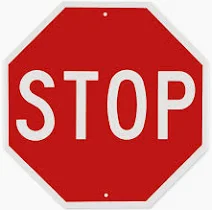

Below we give a possible solution. Don't let us spoil your fun.

In [ ]:
def drive(policy, preprocess, postprocess, task, seconds=20, camera="t2_front"):
    """Closed loop at FPS = 10 Hz for `seconds` of robot time. Returns frames of `camera` for a video."""
    policy.reset()
    frames = []
    for step in range(int(seconds * FPS)):
        action = postprocess(policy.select_action(preprocess(policy_input(task))))
        apply_action(action.squeeze(0).float().cpu().numpy())
        if step % 2 == 0:
            frames.append(render(camera))
    return frames


load_scene(layout)
torch.manual_seed(0)
print(task)
frames = drive(policy, preprocess, postprocess, task)
print("success:", ("on", a, b) in estimate_state())
show_video(frames, fps=5)

How good is it? We ran it on 50 new tasks. On the same axes: the **ceiling** is tutorial 4.1's skills themselves
(they succeeded on every demonstration), the **floor** is a policy that outputs random chunks of actions, and the
**baseline** is SmolVLA *before* fine-tuning, the pretrained model that has never seen this robot:

In [ ]:
#@title Helper: the evaluation figure { display-mode: "form" }
import json
import matplotlib.pyplot as plt

results = json.load(open(f"{DATA_DIR}/results.json"))
fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1, 1.4]})
names = ["random chunks\n(floor)", "SmolVLA, not\nfine-tuned", "SmolVLA,\nfine-tuned", "tutorial 4.1\n(ceiling)"]
keys = ["floor", "base", "finetuned", "ceiling"]
rates = [results["success"][k]["rate"] for k in keys]
errors = np.array([[r - results["success"][k]["low"], results["success"][k]["high"] - r] for k, r in zip(keys, rates)]).T
axes[0].bar(names, rates, yerr=errors, color=["#bbb", "#9ab", "#4a3c9c", "#2a7"], capsize=4)
axes[0].set_ylim(0, 1.05)
axes[0].set_ylabel(f"success rate ({results['n_eval']} new tasks, 95% CI)")
steps = results["by_step"]["steps"]
axes[1].plot(steps, results["by_step"]["rate"], "o-", color="#4a3c9c", label="SmolVLA, fine-tuned for this many steps")
axes[1].axhline(rates[3], color="#2a7", linestyle="--", label="tutorial 4.1 (ceiling)")
axes[1].axhline(rates[0], color="#bbb", linestyle="--", label="random chunks (floor)")
axes[1].set_xlabel("fine-tuning steps")
axes[1].set_ylim(0, 1.05)
axes[1].legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

The fine-tuned policy stacked the right block on 26 of 50 new tasks (52%, 95% interval 39 to 65%). Both references at the bottom scored 0: random chunks of actions never stack anything, and neither does SmolVLA before fine-tuning, so everything the policy can do here came from tutorial 4.1's demonstrations. It is also far from the ceiling: the skills it imitates succeed every time. The curve on the right shows where this comes from. Success is near zero for the first few thousand steps, climbs between 2,000 and 7,000, and then stays at about half; another 13,000 steps of training bought almost nothing. One run is also noisy: the same checkpoint on the same 50 tasks scored 29/50 on a second try, because flow matching starts every chunk from random noise.

Four more tasks, with the same policy, pre-rendered (a rollout takes about 20 s of computing per task, so we recorded
these once and ship them with the data): two that worked and two that did not, each with its instruction.

In [ ]:
from IPython.display import Video

Video(f"{DATA_DIR}/clips/smolvla-four-tasks.mp4", embed=True, width=640)  # front camera, 5 frames per second of robot time

## From pixels to tokens

How does a network turn pixels and words into a motion? SmolVLA cuts every 256x256 camera image into an 8 x 8 grid of
**tokens**, each covering a 32 x 32 square of pixels: 64 per camera, 192 for the three. The instruction becomes up to 48 word
tokens (padded to 48), the joint angles one more: **241 tokens** in all, the *prefix*, which the VLM reads. One camera image, in one
line:

```
256x256 → 512x512 → 32x32 patches of 16 px → SigLIP → 4x4 merge → 64 tokens per camera
```

The collapsed cell opens SmolVLA up so that we can follow a pixel into its token, and later read the attention. We stop
the policy's next scene just before the hand reaches the block it should pick up, and look at what it sees:

In [ ]:
#@title Helper: open up SmolVLA, one stage at a time { display-mode: "form" }
import torch.nn.functional as F
from lerobot.policies.smolvla.smolvlm_with_expert import SmolVLMWithExpertModel

PATCH = 16  # SigLIP cuts a 512x512 image into 32x32 patches of 16x16 pixels
SHUFFLE = 4  # the connector merges 4x4 neighbouring patches into one token: 32x32 patches -> 8x8 = 64 tokens per image


def camera_order(policy):
    """Our camera names in the order the policy reads them (it knows them as camera1, camera2, camera3)."""
    ours = {theirs: mine for mine, theirs in RENAME_MAP.items()}
    return [ours.get(k, k).replace("observation.images.", "") for k in policy.config.image_features]


def token_layout(policy, n_language=48):
    """Which positions of the prefix hold what: {name: slice}. Images first (64 tokens each), then words, then the state."""
    layout, start = {}, 0
    for camera in camera_order(policy):
        layout[camera] = slice(start, start + 64)
        start += 64
    layout["language"] = slice(start, start + n_language)
    layout["state"] = slice(start + n_language, start + n_language + 1)
    return layout


# --- attention: SmolVLA's own function is replaced by one that calls your `attention` (Task 6) and logs its weights ---

attention_log = None  # set to a list to keep every attention pattern computed


def eager_attention_with_log(self, attention_mask, batch_size, head_dim, query_states, key_states, value_states):
    """SmolVLA's attention with the core handed to `attention(Q, K, V, mask)`: grouped-query bookkeeping (15 query heads
    share 5 key/value heads), the transposes and the dtypes stay here."""
    groups = self.num_attention_heads // self.num_key_value_heads
    K = key_states.repeat_interleave(groups, dim=2)  # (batch, keys, heads, head_dim)
    V = value_states.repeat_interleave(groups, dim=2)
    Q = query_states.float().transpose(1, 2)[0]  # (heads, queries, head_dim); the batch is one observation
    K = K.float().transpose(1, 2)[0]
    V = V.float().transpose(1, 2)[0]
    weights, out = attention(Q, K, V, attention_mask[0])  # the student's function; mask: (queries, keys), True = may look
    if attention_log is not None:
        attention_log.append(weights.detach().to("cpu", torch.float16))
    out = out.to(value_states.dtype)[None].permute(0, 2, 1, 3)  # (batch, queries, heads, head_dim)
    return out.reshape(batch_size, -1, self.num_attention_heads * head_dim)


_original_attention = SmolVLMWithExpertModel.eager_attention_forward


def use_our_attention(on=True):
    """Switch SmolVLA between your `attention` (with logging) and its original one."""
    SmolVLMWithExpertModel.eager_attention_forward = eager_attention_with_log if on else _original_attention


@torch.no_grad()
def compare_with_smolvla(policy, preprocess, postprocess, task):
    """One chunk with your attention and one with SmolVLA's, same observation and noise: how far apart are the actions?"""
    chunks = []
    for ours in (True, False):
        use_our_attention(ours)
        torch.manual_seed(0)
        policy.reset()
        chunks.append(postprocess(policy.predict_action_chunk(preprocess(policy_input(task))))[0].float().cpu().numpy())
    use_our_attention(True)
    difference = float(np.abs(chunks[0] - chunks[1]).max())
    if difference < 0.01:  # the two differ only in the order of floating-point operations
        return f"your attention gives the same actions as SmolVLA's: max difference {difference:.3f} rad (numerical noise)"
    return f"your attention differs from SmolVLA's: the 50 actions differ by up to {difference:.3f} rad"


@torch.no_grad()
def act_and_log_attention(policy, preprocess, postprocess, task):
    """One chunk of actions for the current observation, and every attention pattern computed on the way.

    Returns (actions, prefix_attention, action_attention): the 50 actions; per VLM layer, how the 241 prefix tokens
    attend to each other; and per action-expert call, how the 50 action tokens attend to the keys.
    """
    global attention_log
    attention_log = []
    policy.reset()
    batch = preprocess(policy_input(task))
    chunk = policy.predict_action_chunk(batch)
    log, attention_log = attention_log, None
    actions = postprocess(chunk)[0].float().cpu().numpy()
    prefix = [p for p in log if p.shape[-2] == p.shape[-1]]  # the VLM: the prefix attending to itself
    expert = [p for p in log if p.shape[-2] == policy.config.chunk_size]  # the action expert: 50 queries
    return actions, prefix, expert


def image_heatmap(weights_over_tokens):
    """64 attention weights (one per image token) as an 8x8 map, upsampled to the size of the camera image."""
    grid = torch.as_tensor(weights_over_tokens, dtype=torch.float32).reshape(1, 1, 8, 8)
    return F.interpolate(grid, size=(IMAGE_SIZE, IMAGE_SIZE), mode="nearest")[0, 0].numpy()


def show_attention(images, attention_over_prefix, layout, title=""):
    """The share of attention that lands on each image token, drawn over the three camera images."""
    total = float(attention_over_prefix.sum())
    fig, axes = plt.subplots(1, len(CAMERAS), figsize=(4 * len(CAMERAS), 4))
    vmax = max(float(attention_over_prefix[layout[c]].max()) for c in CAMERAS)
    for ax, camera in zip(axes, CAMERAS):
        weights = attention_over_prefix[layout[camera]]
        ax.imshow(images[camera])
        ax.imshow(image_heatmap(weights), cmap="magma", alpha=0.55, vmin=0, vmax=vmax)
        ax.set_title(f"{camera}: {100 * float(weights.sum()) / total:.0f}% of the attention")
        ax.axis("off")
    rest = {k: 100 * float(attention_over_prefix[layout[k]].sum()) / total for k in ("language", "state")}
    fig.suptitle(f"{title}   (words: {rest['language']:.0f}%, state: {rest['state']:.0f}%)")
    plt.tight_layout()
    plt.show()


def draw_patch_grid(image, every=PATCH * IMAGE_SIZE // 512, highlight=None, color="cyan", number=False):
    """The camera image with SigLIP's patch grid on it (in the image's own pixels), optionally one token's 4x4 block.
    number=True writes each token's index (0 to 63, row by row) in its square."""
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.imshow(image)
    for x in range(0, IMAGE_SIZE + 1, every):
        ax.axhline(x - 0.5, color="white", linewidth=0.3)
        ax.axvline(x - 0.5, color="white", linewidth=0.3)
    if number:
        size = every * SHUFFLE
        for t in range(64):
            row, col = divmod(t, 8)
            ax.text(col * size + 3, row * size + 3, str(t), color="white", fontsize=7, va="top", ha="left",
                    bbox=dict(boxstyle="square,pad=0.1", facecolor="black", alpha=0.5, linewidth=0))
    if highlight is not None:
        row, col = divmod(highlight, 8)
        size = every * SHUFFLE
        ax.add_patch(plt.Rectangle((col * size - 0.5, row * size - 0.5), size, size, fill=False, color=color, linewidth=2.5))
    ax.axis("off")
    plt.show()


# --- where a point of the world lands in a camera image (the pinhole camera of tutorial 3.1) ---

def world_to_pixel(camera, point, size=IMAGE_SIZE):
    """(row, column) of a world point in the size x size image of the named camera (one of CAMERAS)."""
    cam = data.cam(MUJOCO_CAMERA[camera])
    fovy = model.cam_fovy[model.camera(MUJOCO_CAMERA[camera]).id]
    focal = 0.5 * size / np.tan(np.deg2rad(fovy) / 2)
    p = cam.xmat.reshape(3, 3).T @ (np.asarray(point) - cam.xpos)  # the point in the camera's frame (it looks along -z)
    return size / 2 - focal * p[1] / -p[2], size / 2 + focal * p[0] / -p[2]


# --- the flow head, step by step: record the 50-action chunk at every one of its 10 integration steps ---
import lerobot.policies.smolvla.modeling_smolvla as smolvla_module

_euler_integrate = smolvla_module.euler_integrate
flow_log = None  # set to a list to keep x_t at every integration step


def euler_integrate_with_log(denoise_fn, noise, num_steps, **kwargs):
    def logged(x_t, time):
        if flow_log is not None:
            flow_log.append((float(time[0]), x_t[0].detach().float().cpu().numpy().copy()))
        return denoise_fn(x_t, time)
    x_0 = _euler_integrate(logged, noise, num_steps, **kwargs)
    if flow_log is not None:
        flow_log.append((0.0, x_0[0].detach().float().cpu().numpy().copy()))
    return x_0


smolvla_module.euler_integrate = euler_integrate_with_log

In [ ]:
layout, a, b, task = random_task(np.random.default_rng([1, 0]))
load_scene(layout)
torch.manual_seed(0)
run_policy(policy, preprocess, postprocess, task, max_seconds=2.5, render_every=10**9)  # 2.5 s in: on the way to the block
images = observe_images()
print(task, "| the block to move:", a, layout[a][0], "| onto:", b, layout[b][0])
plt.figure(figsize=(12, 4))
plt.imshow(np.concatenate([images[c] for c in CAMERAS], axis=1))
plt.axis("off")
plt.show()

Tokens are numbered row by row on the 8 x 8 grid, and each covers $32 \times 32$ pixels ($32 = 256 / 8$), so the pixel
at row $r$, column $c$ of a camera image belongs to

$$\text{token}(r, c) = 8 \left\lfloor r / 32 \right\rfloor + \left\lfloor c / 32 \right\rfloor .$$

⚒ **Task 5**: Write `token_of_pixel(row, col)` (0 to 63). The cell then finds the token of the block that the policy
must pick up: `world_to_pixel(camera, point)` (the pinhole camera model of tutorial 3.1, in the helper) gives the
(row, column) of the block's position `data.body(a).xpos` in the `"front"` image. The solution also draws the numbered
token grid and prints where each camera, the words and the state sit among the 241 tokens of the prefix.

In [ ]:
def token_of_pixel(row, col):
    """Which of an image's 64 tokens covers pixel (row, col): tokens are numbered row by row on the 8 x 8 grid."""
    return 0  # your code here


row, col = world_to_pixel("front", data.body(a).xpos)
token = token_of_pixel(row, col)
print(f"pixel ({row:.0f}, {col:.0f}) of the 256x256 front image -> token {token} of 64")

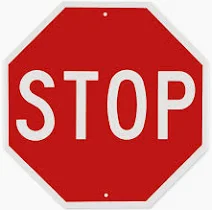

Below we give a possible solution. Don't let us spoil your fun.

In [ ]:
def token_of_pixel(row, col):
    """Which of an image's 64 tokens covers pixel (row, col): tokens are numbered row by row on the 8 x 8 grid."""
    return 8 * int(row // 32) + int(col // 32)


row, col = world_to_pixel("front", data.body(a).xpos)
token = token_of_pixel(row, col)
print(f"pixel ({row:.0f}, {col:.0f}) of the 256x256 front image -> token {token} of 64")
layout_of_prefix = token_layout(policy)
print("the prefix:", ", ".join(f"{name} {s.start}-{s.stop - 1}" if s.stop - s.start > 1 else f"{name} {s.start}"
                               for name, s in layout_of_prefix.items()))
draw_patch_grid(images["front"], highlight=token, number=True)

## Where does the policy look?

The action expert generates the 50 actions of a chunk with **attention**. With queries $Q$, keys $K$ and values $V$
of width $d$, and a boolean mask that says which query may look at which key:

$$\text{scores} = \frac{Q K^\top}{\sqrt{d}}, \qquad \text{scores}_{ij} = -\infty \text{ where } \text{mask}_{ij} \text{ is false}, \qquad
\text{weights} = \text{softmax}(\text{scores}), \qquad \text{output} = \text{weights} \; V .$$

* the **queries** come from the **50 future actions** that the policy is generating. Each one asks: *what in the world
  should I depend on?*
* the **keys** come from the **241 prefix tokens**. Each says: *this is what I am*.
* the **values** come from the same 241 tokens, and are what flows into the actions: *this is what I contribute*.

So the attention weights of the action queries over the image tokens tell us **where, in the three images, the motion
is looking**.

⚒ **Task 6**, first half: Write `attention(Q, K, V, mask)` for `Q` of shape `(heads, queries, d)`, `K` and `V` of
shape `(heads, keys, d)` and a boolean `mask` of shape `(queries, keys)`; it returns `(weights, output)`, of shapes
`(heads, queries, keys)` and `(heads, queries, d)`. The helper above plugs it into SmolVLA in place of its own
attention (the grouped-query bookkeeping stays in the helper) and records the weights you return. The cell then
generates one chunk with your attention and one with SmolVLA's original, from the same observation and the same
noise, and prints how far apart the 50 actions are.

In [ ]:
def attention(Q, K, V, mask):
    """Scaled dot-product attention. Returns (weights, output)."""
    weights = torch.full((Q.shape[0], Q.shape[1], K.shape[1]), 1.0 / K.shape[1], device=Q.device)  # your code here (this looks everywhere equally)
    return weights, weights @ V


use_our_attention(True)
print(compare_with_smolvla(policy, preprocess, postprocess, task))

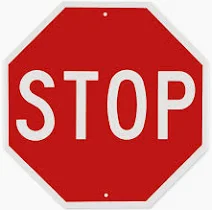

Below we give a possible solution. Don't let us spoil your fun.

In [ ]:
def attention(Q, K, V, mask):
    """Scaled dot-product attention. Returns (weights, output)."""
    scores = Q @ K.transpose(-1, -2) / Q.shape[-1] ** 0.5  # how well each query matches each key
    scores = scores.masked_fill(~mask, torch.finfo(scores.dtype).min)  # -inf in the math; the smallest float avoids NaN rows
    weights = torch.softmax(scores, dim=-1)  # each query's attention: a distribution over the keys
    return weights, weights @ V  # each query gets the attention-weighted average of the values


use_our_attention(True)
print(compare_with_smolvla(policy, preprocess, postprocess, task))

Now the question. Each of the 50 action queries attends over the 241 prefix tokens; the cell shows the last flow step,
mean over layers, heads and queries. Before you run it: **the instruction names two blocks, and the camera sees three.
Where does the action half look?**

In [ ]:
layout_of_prefix = token_layout(policy)
actions, prefix_attention, action_attention = act_and_log_attention(policy, preprocess, postprocess, task)
print(f"{len(action_attention)} action-expert attention calls, each (heads, 50 queries, keys): {tuple(action_attention[0].shape)}")

# the cross-attention calls (keys = the 241 prefix tokens) of the last flow step, averaged over heads and the 50 queries
cross = [p for p in action_attention if p.shape[-1] == 241]
per_step = len(cross) // policy.config.num_steps
last_step = torch.stack(cross[-per_step:]).float().mean(dim=(0, 1, 2))  # (241,)
show_attention(images, last_step.numpy(), layout_of_prefix, title=f"the action queries attend to... ('{task}')")

Is that picture telling us something? We measured it the same way on 20 tasks, counting the attention that lands on each block in the two fixed cameras (in the wrist view, the nearest block fills half the image, so it would win by size alone). Fine-tuning roughly **doubled** the attention on the blocks: 0.08 on the block to move, against 0.04 before fine-tuning and 0.03 by chance, higher than before on all 20 tasks. But averaged over every layer, head and action, it does **not** single out the block it should move: the block to put it on gets about as much (0.08; the block to move wins on only 10 of 20 tasks), and the third block, which is in neither instruction, gets 0.07. The policy learned *where the blocks are*; *which* one matters is not visible in the average. Individual heads can be far more selective, and an average over 120 heads can hide them. Task 6 asks how much the instruction moves this picture.

Second half of ⚒ **Task 6**: make the policy look elsewhere without touching the world. Change **only the instruction**:
swap the colour of the block to move for the colour of the third block on the table (the one that is in neither
instruction), and draw the attention again with `act_and_log_attention` and `show_attention`, as above. Does it move?

In [ ]:
# your code here

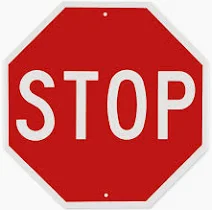

Below we give a possible solution. Don't let us spoil your fun.

In [ ]:
third = next(block for block in layout if block not in (a, b))
other_task = task.replace(layout[a][0], layout[third][0])
_, _, other_attention = act_and_log_attention(policy, preprocess, postprocess, other_task)
cross = [p for p in other_attention if p.shape[-1] == 241]
show_attention(images, torch.stack(cross[-per_step:]).float().mean(dim=(0, 1, 2)).numpy(), layout_of_prefix,
               title=f"same scene, other instruction: '{other_task}'")

And what does the arm *do* with the swapped instruction? A rollout costs about 20 s of computing, so this one is
pre-rendered, from the same scene: the real instruction on the left, the swapped one on the right.

In [ ]:
Video(f"{DATA_DIR}/clips/smolvla-word-swap.mp4", embed=True, width=640)  # left: the instruction; right: its swap

❓ **Which parts of tutorials 1.2 to 4.1 does this network replace, and which of their checks have we lost? If the policy
puts the block on the wrong one, who notices?**

---

**Stop 2** — slides. Live: the Task 5 grid, then the Task 6 attention, then the word swap.

---

⚒ **Bonus task**: The opposite experiment: keep the instruction, and **paint over** the target block in the front image
(fill its 32 x 32 square with the colour of the table, `images["front"][...] = ...`) before computing the attention. What
happens to the attention, and to the first actions of the chunk? `policy_input` reads the cameras with
`observe_images()`, so replace that function for a moment with one that returns your edited images.

In [ ]:
# your code here

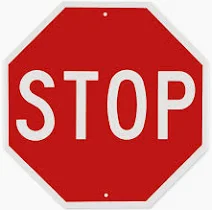

Below we give a possible solution. Don't let us spoil your fun.

In [ ]:
painted = {c: im.copy() for c, im in images.items()}
row, col = world_to_pixel("front", data.body(a).xpos)
r, c = int(row // 32) * 32, int(col // 32) * 32
painted["front"][r:r + 32, c:c + 32] = painted["front"][min(r + 40, 250), c:c + 32].mean(axis=0)
_real_observe = observe_images
observe_images = lambda: painted
painted_actions, _, painted_attention = act_and_log_attention(policy, preprocess, postprocess, task)
observe_images = _real_observe
cross = [p for p in painted_attention if p.shape[-1] == 241]
show_attention(painted, torch.stack(cross[-per_step:]).float().mean(dim=(0, 1, 2)).numpy(), layout_of_prefix,
               title="the target block painted over in the front camera")
print("first 10 joint targets differ by", np.abs(painted_actions[:10, :6] - actions[:10, :6]).max().round(3), "rad at most")

# Part 3 — Plan: an LLM in the task planner's seat

The third route of the lecture, the **hybrid**: a learned proposer and a classical checker that must agree on the
symbols. This part is standalone (nothing above needs it) and runs on a CPU in seconds.

The blocks world of tutorial 1.1, twenty random problems, and a small open LLM (Qwen3-4B) that gets the rules in English
and one worked example, and writes a plan. The LLM brings knowledge that nobody wrote down for it: what "stack" means,
what a plan looks like. We do not trust the plan: a classical **checker** tests it.

So that the notebook runs anywhere in seconds, it replays answers that we recorded from the LLM (`LLM_BACKEND =
"cached"`). With a GPU you can switch to `"open"` and watch the model answer live; prompts that are not in the cache are
then answered by the model itself.

In [ ]:
# unified-planning: the planning framework from tutorial 1. up-fast-downward: the Fast Downward planner. Setup
# installed both; this installs them only if they are missing (into this kernel), so Part 3 also runs on its own.
import importlib.util
if importlib.util.find_spec("unified_planning") is None or importlib.util.find_spec("up_fast_downward") is None:
    %pip install -q unified-planning up-fast-downward

In [ ]:
LLM_BACKEND = "cached"  #@param ["cached", "open", "open-thinking", "api"]

In [ ]:
# the extra libraries are only needed by the "open", "open-thinking" and "api" backends
import importlib.util
if LLM_BACKEND in ("open", "open-thinking") and importlib.util.find_spec("transformers") is None:
    %pip install -q transformers accelerate
elif LLM_BACKEND == "api" and importlib.util.find_spec("anthropic") is None:
    %pip install -q anthropic

In [ ]:
#@title Helper: the LLM backend and `ask(prompt, model)` { display-mode: "form" }
import hashlib
import json
import os
import time
import urllib.request

OPEN_MODEL = "Qwen/Qwen3-4B-Instruct-2507"  # the open model: answers right away
THINKING_MODEL = "Qwen/Qwen3-4B-Thinking-2507"  # the same size, trained to reason before it answers
API_MODEL = "claude-opus-5-5"  # the API model (needs an Anthropic API key)
REASONING_MODELS = {THINKING_MODEL, API_MODEL}  # models that think before they answer

MAX_NEW_TOKENS = 768  # the answer budget of the instruct model (greedy decoding)
MAX_THINKING_TOKENS = 16384  # the budget of the thinking model: its reasoning and its answer together
THINKING_SAMPLING = dict(do_sample=True, temperature=0.6, top_p=0.95, top_k=20, min_p=0.0)  # the model card's recommendation
END_OF_THINKING = "</think>"

CACHE_PATH = f"{DATA_DIR}/a1_llm_cache.json"  # the recorded answers, downloaded with the data in Setup
CACHE_URL = f"{DRIVE_FOLDER}/a1_llm_cache.json"  # not reached when Setup downloaded the data folder

# the model that answers by default; recorded answers exist for the two open models
MODEL_ID = {"cached": OPEN_MODEL, "open": OPEN_MODEL, "open-thinking": THINKING_MODEL, "api": API_MODEL}[LLM_BACKEND]


def cache_key(model_id, prompt):
    return hashlib.sha256(json.dumps([model_id, prompt]).encode("utf-8")).hexdigest()


def load_cache():
    if not os.path.exists(CACHE_PATH):
        os.makedirs(os.path.dirname(CACHE_PATH), exist_ok=True)
        print("downloading the recorded LLM answers...")
        urllib.request.urlretrieve(CACHE_URL, CACHE_PATH)
    with open(CACHE_PATH) as f:
        return json.load(f)


def save_cache():
    # write to a temporary file first, so that an interrupted run never leaves a broken cache behind
    os.makedirs(os.path.dirname(CACHE_PATH), exist_ok=True)
    with open(CACHE_PATH + ".tmp", "w") as f:
        json.dump(CACHE, f, indent=0, sort_keys=True)
    os.replace(CACHE_PATH + ".tmp", CACHE_PATH)


_loaded = {}


def load_open_model(model_id):
    """Load an open model (and unload the other one: a T4 has room for one at a time)."""
    import torch
    from transformers import AutoModelForCausalLM, AutoTokenizer

    if model_id not in _loaded:
        _loaded.clear()
        device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
        if device == "cpu":
            print("warning: no GPU found, the open model will be very slow on the CPU")
        dtype = torch.float32 if device == "cpu" else torch.float16
        tokenizer = AutoTokenizer.from_pretrained(model_id)
        model = AutoModelForCausalLM.from_pretrained(model_id, dtype=dtype).to(device).eval()
        _loaded[model_id] = (tokenizer, model, device)
    return _loaded[model_id]


def split_thinking(tokenizer, output_ids):
    """Split the thinking model's output into (reasoning, answer). The answer is empty if the reasoning never ended."""
    end = tokenizer.convert_tokens_to_ids(END_OF_THINKING)
    output_ids = [t for t in output_ids if t != tokenizer.pad_token_id]
    if end in output_ids:
        i = output_ids.index(end)
        thinking, answer, finished = output_ids[:i], output_ids[i + 1:], True
    else:
        thinking, answer, finished = output_ids, [], False
    decode = lambda ids: tokenizer.decode(ids, skip_special_tokens=True).strip()
    return dict(thinking=decode(thinking), response=decode(answer), finished_thinking=finished,
                thinking_tokens=len(thinking), answer_tokens=len(answer))


def generate_open(prompt, model_id, seed):
    """One answer of an open model: greedy for the instruct model, sampled (with a fixed seed) for the thinking model."""
    import torch

    tokenizer, model, device = load_open_model(model_id)
    inputs = tokenizer.apply_chat_template(
        [{"role": "user", "content": prompt}], add_generation_prompt=True, return_tensors="pt", return_dict=True
    ).to(device)
    start_time = time.time()
    with torch.no_grad():
        if model_id == THINKING_MODEL:
            torch.manual_seed(seed)
            output = model.generate(**inputs, max_new_tokens=MAX_THINKING_TOKENS, **THINKING_SAMPLING)
        else:
            output = model.generate(**inputs, max_new_tokens=MAX_NEW_TOKENS, do_sample=False, temperature=None, top_p=None, top_k=None)
    output_ids = output[0, inputs["input_ids"].shape[1]:].tolist()
    if model_id == THINKING_MODEL:
        return dict(split_thinking(tokenizer, output_ids), seconds=time.time() - start_time, batch_size=1)
    return dict(response=tokenizer.decode(output_ids, skip_special_tokens=True))


_api_client = None


def generate_api(prompt):
    """One request to the Anthropic API. The key is read from the Colab secrets or the ANTHROPIC_API_KEY variable."""
    global _api_client
    import anthropic

    if _api_client is None:
        api_key = os.environ.get("ANTHROPIC_API_KEY")
        if api_key is None:
            try:
                from google.colab import userdata
                api_key = userdata.get("ANTHROPIC_API_KEY")
            except Exception:
                raise RuntimeError("No API key: add ANTHROPIC_API_KEY to the Colab secrets (the key icon on the left) or to the environment.")
        _api_client = anthropic.Anthropic(api_key=api_key)
    response = _api_client.beta.messages.create(
        model=API_MODEL,
        max_tokens=16000,
        output_config={"effort": "medium"},
        betas=["server-side-fallback-2026-07-01"],
        fallbacks="default",  # if a request is declined, the API retries it on a fallback model
        messages=[{"role": "user", "content": prompt}],
    )
    if response.stop_reason == "refusal":
        raise RuntimeError("The API declined this request.")
    return dict(response="".join(block.text for block in response.content if block.type == "text"))


CALL_LOG = []  # (model, cache key) of every call, in order


def ask(prompt, model=None):
    """Send one prompt to an LLM (by default MODEL_ID) and return its answer as a string.

    Recorded answers are replayed whenever they exist. The backend decides who answers a prompt that was not recorded."""
    model = model or MODEL_ID
    key = cache_key(model, prompt)
    CALL_LOG.append((model, key))
    if key in CACHE:
        return CACHE[key]["response"]
    if model == API_MODEL and LLM_BACKEND == "api":
        entry = generate_api(prompt)
    elif model in (OPEN_MODEL, THINKING_MODEL) and LLM_BACKEND in ("open", "open-thinking"):
        entry = generate_open(prompt, model, seed=int(key[:8], 16))
    else:
        raise LookupError(
            f"This prompt is not among the recorded answers of {model} (did you change a prompt, or the wording of a message?). "
            'The "cached" backend can only replay prompts that we recorded. Switch LLM_BACKEND to "open" or "open-thinking" '
            '(needs a GPU: Runtime > Change runtime type > T4 GPU) or to "api" (needs an API key) and re-run the setup cells.'
        )
    CACHE[key] = dict(entry, model=model)
    save_cache()  # after every call, so that an interrupted run loses nothing
    return entry["response"]


CACHE = load_cache()
for model_id in (OPEN_MODEL, THINKING_MODEL):
    print(f"{model_id}: {sum(entry['model'] == model_id for entry in CACHE.values())} recorded answers")
print(f"backend: {LLM_BACKEND}, default model: {MODEL_ID}")

In [ ]:
#@title Helper: the blocks world: domain, problems, prompts, parser and validator { display-mode: "form" }
DOMAIN = """
(define (domain blocks)
    (:requirements :strips :typing)
    (:types block robot)
    (:predicates
        (on ?x - block ?y - block)
        (ontable ?x - block)
        (clear ?x - block)
        (handempty ?r - robot)
        (holding ?x - block)
    )

    (:action pick-up
        :parameters (?x - block ?r - robot)
        :precondition (and (clear ?x) (ontable ?x) (handempty ?r))
        :effect (and (not (ontable ?x))
                     (not (clear ?x))
                     (not (handempty ?r))
                     (holding ?x))
    )

    (:action put-down
        :parameters (?x - block ?r - robot)
        :precondition (holding ?x)
        :effect (and (not (holding ?x))
                     (clear ?x)
                     (handempty ?r)
                     (ontable ?x))
    )

    (:action stack
        :parameters (?x - block ?y - block ?r - robot)
        :precondition (and (holding ?x) (clear ?y))
        :effect (and (not (holding ?x))
                     (not (clear ?y))
                     (clear ?x)
                     (handempty ?r)
                     (on ?x ?y))
    )

    (:action unstack
        :parameters (?x - block ?y - block ?r - robot)
        :precondition (and (on ?x ?y) (clear ?x) (handempty ?r))
        :effect (and (holding ?x)
                     (clear ?y)
                     (not (clear ?x))
                     (not (handempty ?r))
                     (not (on ?x ?y)))
    )
)
"""


import random

import unified_planning as up
from unified_planning.io import PDDLReader
from unified_planning.plans import ActionInstance, SequentialPlan
from unified_planning.shortcuts import OneshotPlanner, PlanValidator, SequentialSimulator, get_environment

get_environment().credits_stream = None  # keep the output clean (planners print their credits otherwise)


# two helpers copied from tutorial 1.1
def true_facts(state, problem):
    """The set of facts (grounded fluent expressions) that hold in a state."""
    # problem.initial_values lists every grounded fluent, which is a convenient way to enumerate them all
    return {fact for fact in problem.initial_values if state.get_value(fact).is_true()}


def goal_atoms(problem):
    """The goal of the problem as a list of atomic facts (flattening conjunctions)."""
    atoms = []

    def collect(expression):
        if expression.is_and():
            for arg in expression.args:
                collect(arg)
        else:
            atoms.append(expression)

    for goal in problem.goals:
        collect(goal)
    return atoms


BLOCK_NAMES = "abcdefg"


def random_towers(blocks, rng):
    """A random arrangement of the blocks into towers (lists from bottom to top)."""
    towers = []
    for block in rng.sample(blocks, len(blocks)):
        choice = rng.randrange(len(towers) + 1)  # the top of an existing tower, or the table
        if choice == len(towers):
            towers.append([block])
        else:
            towers[choice].append(block)
    return towers


def on_facts(towers):
    return [f"(on {upper} {lower})" for tower in towers for lower, upper in zip(tower, tower[1:])]


def make_problem_pddl(name, blocks, init_towers, goal_facts):
    init = ["(handempty rob)"]
    for tower in init_towers:
        init.append(f"(ontable {tower[0]})")
        init.append(f"(clear {tower[-1]})")
    init += on_facts(init_towers)
    return f"""
(define (problem {name})
    (:domain blocks)
    (:objects {" ".join(blocks)} - block rob - robot)
    (:init {" ".join(init)})
    (:goal (and {" ".join(goal_facts)}))
)
"""


def generate_problems(n_problems=20, seed=0):
    """n_problems random blocks world problems with 4 to 7 blocks. The goal places blocks on blocks, as in tutorial 1."""
    rng = random.Random(seed)
    problems = []
    for i in range(n_problems):
        blocks = list(BLOCK_NAMES[: 4 + i % 4])
        init_towers = random_towers(blocks, rng)
        while True:
            goal = on_facts(random_towers(blocks, rng))
            if goal and not set(goal) <= set(on_facts(init_towers)):  # a goal that is not already true
                break
        problems.append(make_problem_pddl(f"bw-{i + 1:02d}", blocks, init_towers, goal))
    return problems


N_PROBLEMS = 20
PROBLEM_PDDLS = generate_problems(N_PROBLEMS, seed=2026)
problems = [PDDLReader().parse_problem_string(DOMAIN, pddl) for pddl in PROBLEM_PDDLS]
print(PROBLEM_PDDLS[0])


def n_blocks(problem):
    return sum(1 for o in problem.all_objects if o.type.name != "robot")


fd_plans = []
for problem in problems:
    with OneshotPlanner(name="fast-downward") as planner:
        result = planner.solve(problem)
    with PlanValidator(problem_kind=problem.kind, plan_kind=result.plan.kind) as validator:
        valid = validator.validate(problem, result.plan).status.name == "VALID"
    fd_plans.append(result.plan)
    print(f"{problem.name}: {n_blocks(problem)} blocks, "
          f"{len(goal_atoms(problem))} goal facts, Fast Downward plan of length {len(result.plan.actions)}, valid: {valid}")


class Vocabulary:
    """How the facts and objects of a domain are written in English."""

    def __init__(self, intro, templates):
        self.intro = intro
        self.templates = templates  # predicate name -> format string, {0} and {1} are the arguments

    def fact(self, fact, names=None):
        """One fact (or one precondition/effect with parameters) in English. names renames parameters, e.g. x -> X."""
        names = names or {}
        args = [names.get(str(arg), str(arg)) for arg in fact.args]
        return self.templates[fact.fluent().name].format(*args)

    def facts(self, facts, names=None):
        """A list of facts in English, in a fixed order (predicate first, then arguments)."""
        order = list(self.templates)
        facts = sorted(facts, key=lambda f: (order.index(f.fluent().name), [str(a) for a in f.args]))
        return english_list([self.fact(f, names) for f in facts])

    @staticmethod
    def action(action_instance):
        """An action instance in the syntax the LLM uses: no commas, and no robot (there is only one)."""
        args = [str(p) for p in action_instance.actual_parameters if p.object().type.name != "robot"]
        return "(" + " ".join([action_instance.action.name] + args) + ")"


def english_list(items, conjunction="and"):
    if len(items) <= 1:
        return "".join(items)
    return ", ".join(items[:-1]) + f" {conjunction} " + items[-1]


BLOCKS_VOCABULARY = Vocabulary(
    intro="I am working with a set of blocks. Here are the actions I can do. In each action, X and Y stand for blocks.",
    templates={
        "handempty": "the hand is empty",
        "holding": "the hand is holding block {0}",
        "ontable": "block {0} is on the table",
        "on": "block {0} is on top of block {1}",
        "clear": "block {0} is clear",
    },
)


def action_parameter_names(action):
    """Parameter display names for the prompt: x -> X, y -> Y. The robot parameter is not shown."""
    return {p.name: p.name.upper() for p in action.parameters if p.type.name != "robot"}


def flatten(expression):
    return [a for arg in expression.args for a in flatten(arg)] if expression.is_and() else [expression]


def describe_domain(problem, vocab):
    lines = [vocab.intro, ""]
    for action in problem.actions:
        names = action_parameter_names(action)
        preconditions = [atom for p in action.preconditions for atom in flatten(p)]
        adds = [e.fluent for e in action.effects if e.value.is_true()]
        deletes = [e.fluent for e in action.effects if e.value.is_false()]
        lines.append("(" + " ".join([action.name] + list(names.values())) + ")")
        lines.append(f"    It can only be done if {vocab.facts(preconditions, names)}.")
        lines.append(f"    Afterwards, {vocab.facts(adds, names)}.")
        lines.append(f"    It is then no longer true that {vocab.facts(deletes, names).replace(' and ', ' or ')}.")
    lines.append("")
    lines.append("Facts that an action does not mention stay as they were. Actions are done one at a time.")
    return "\n".join(lines)


def describe_problem(problem, vocab):
    with SequentialSimulator(problem) as simulator:
        initial_facts = true_facts(simulator.get_initial_state(), problem)
    return (f"As initial conditions I have that {vocab.facts(initial_facts)}.\n"
            f"My goal is to have that {vocab.facts(goal_atoms(problem))}.")


def plan_text(actions):
    return "[PLAN]\n" + "\n".join(Vocabulary.action(a) for a in actions) + "\n[PLAN END]"


def answer_instruction(model):
    """Models that answer right away are asked for the plan only; models that reason first are free to think."""
    return "" if model in REASONING_MODELS else " Answer with the plan only, without explanations."


def planning_prompt(problem, vocab, example_problem, example_plan, model=None):
    return f"""{describe_domain(problem, vocab)}

Here is an example problem and a plan that solves it.

[STATEMENT]
{describe_problem(example_problem, vocab)}

{plan_text(example_plan)}

Now solve the following problem. Write the plan between [PLAN] and [PLAN END], one action per line, in the same format as in the example.{answer_instruction(model or MODEL_ID)}

[STATEMENT]
{describe_problem(problem, vocab)}"""


EXAMPLE_PROBLEM = """
(define (problem blocks-4)
    (:domain blocks)
    (:objects
        a b c d - block
        rob - robot
    )
    (:init
        (ontable a) (on b a) (clear b)
        (ontable c) (clear c)
        (ontable d) (clear d)
        (handempty rob)
    )
    (:goal (and (on c a) (on b d)))
)
"""
example_problem = PDDLReader().parse_problem_string(DOMAIN, EXAMPLE_PROBLEM)


def make_action(problem, name, *args):
    """An action instance from names, e.g. make_action(problem, "stack", "b", "d", "rob")."""
    return ActionInstance(problem.action(name), [problem.object(arg) for arg in args])


# the plan that Fast Downward found for this problem in tutorial 1.1
example_plan = [
    make_action(example_problem, "unstack", "b", "a", "rob"),
    make_action(example_problem, "stack", "b", "d", "rob"),
    make_action(example_problem, "pick-up", "c", "rob"),
    make_action(example_problem, "stack", "c", "a", "rob"),
]

prompt = planning_prompt(problems[0], BLOCKS_VOCABULARY, example_problem, example_plan)
print(prompt)


import re


class PlanParseError(Exception):
    pass


def plan_block(reply):
    """The text between the last [PLAN] and the [PLAN END] after it (the whole reply if there is no [PLAN])."""
    start = reply.rfind("[PLAN]")
    if start == -1:
        return reply
    block = reply[start + len("[PLAN]"):]
    end = block.find("[PLAN END]")
    return block if end == -1 else block[:end]


def parse_plan(reply, problem):
    """Turn the LLM's reply into a list of UP action instances of `problem`."""
    robot = next(o for o in problem.all_objects if o.type.name == "robot")
    plan = []
    for words in re.findall(r"\(([^()]*)\)", plan_block(reply)):  # everything in parentheses, anything else is ignored
        words = words.replace(",", " ").lower().split()
        if not words:
            continue
        name, args = words[0], words[1:]
        if not problem.has_action(name):
            raise PlanParseError(f"there is no action called {name}")
        action = problem.action(name)
        block_parameters = [p for p in action.parameters if p.type.name != "robot"]
        if len(args) != len(block_parameters):
            raise PlanParseError(f"({' '.join(words)}) should have {len(block_parameters)} argument(s), not {len(args)}")
        for arg in args:
            if not problem.has_object(arg):
                raise PlanParseError(f"there is no object called {arg}")
        args = iter(args)
        parameters = [robot if p.type.name == "robot" else problem.object(next(args)) for p in action.parameters]
        plan.append(ActionInstance(action, parameters))
    return plan


TEST_REPLY = """Let me think. First I should (unstack b a), then...
[PLAN]
1. (unstack b a)
2. (stack b d)
(pick-up c)
(stack c a)
[PLAN END]
I hope this helps!"""
print(parse_plan(TEST_REPLY, example_problem))


def is_valid(problem, actions):
    with PlanValidator(problem_kind=problem.kind) as validator:
        return validator.validate(problem, SequentialPlan(actions)).status.name == "VALID"


print("the test reply is valid for the example problem:", is_valid(example_problem, parse_plan(TEST_REPLY, example_problem)))


def grounded_preconditions(action_instance):
    """The preconditions of an action instance as a list of facts, with the actual objects in place of the parameters."""
    expression_manager = get_environment().expression_manager
    substitution = {expression_manager.ParameterExp(p): v for p, v in zip(action_instance.action.parameters, action_instance.actual_parameters)}
    return [atom.substitute(substitution) for p in action_instance.action.preconditions for atom in flatten(p)]


print(make_action(example_problem, "stack", "b", "d", "rob"), "requires",
      grounded_preconditions(make_action(example_problem, "stack", "b", "d", "rob")))

The collapsed cell defined the twenty problems (`problems`), solved them with Fast Downward (`fd_plans`: every one in a
fraction of a second, our **ceiling**), and built the prompt. Here is what the LLM is asked for the first problem, and
what it answers:

In [ ]:
print(prompt)
print("=" * 80)
reply = ask(prompt)
print(reply)

It looks like a plan, in exactly the right format. Is it one? `try_direct` asks the LLM for a plan for each of the twenty
problems, parses it, and checks it with the validator:

In [ ]:
def try_direct(problem, vocab=BLOCKS_VOCABULARY, example=(example_problem, example_plan)):
    """Ask once, parse, validate. Returns (outcome, reply, plan)."""
    reply = ask(planning_prompt(problem, vocab, *example))
    try:
        plan = parse_plan(reply, problem)
    except PlanParseError as error:
        return f"unreadable ({error})", reply, None
    return ("valid" if is_valid(problem, plan) else "invalid"), reply, plan


direct_outcomes = []
for problem, fd_plan in zip(problems, fd_plans):
    outcome, reply, llm_plan = try_direct(problem)
    direct_outcomes.append(outcome)
    length = "-" if llm_plan is None else len(llm_plan)
    print(f"{problem.name}: LLM plan length {length:>2}, Fast Downward {len(fd_plan.actions):>2}: {outcome}")
print(f"\ndirect planning: {direct_outcomes.count('valid')} of {len(problems)} plans are valid")

**None of the 20 plans is valid.** The format is always right; the plans are not. Here is one of them, for a problem
where it could be read but not executed. Read it before you go on: **does it run?**

In [ ]:
# the first problem on which the LLM's plan breaks a precondition somewhere (problem 0's plan runs, but misses the goal)
def runs(problem, plan):
    with SequentialSimulator(problem) as simulator:
        state = simulator.get_initial_state()
        for action in plan:
            if not simulator.is_applicable(state, action):
                return False
            state = simulator.apply(state, action)
    return True


problem = next(p for p, o in zip(problems, direct_outcomes) if o == "invalid" and not runs(p, parse_plan(ask(planning_prompt(p, BLOCKS_VOCABULARY, example_problem, example_plan)), p)))
print(problem.name)
print(describe_problem(problem, BLOCKS_VOCABULARY))
print()
reply = ask(planning_prompt(problem, BLOCKS_VOCABULARY, example_problem, example_plan))
print(reply)

## The checker

The validator answers with one bit: `VALID` or `INVALID`. To find out *where* a plan breaks, and *why*, we step through
it with the sequential simulator of tutorial 1.1: an action can be done only if all of its **preconditions** hold in the
current state. `grounded_preconditions(action)` (in the helper above) lists them, with the plan's blocks in place of the
parameters: for `(stack b d)`, *the robot holds b* and *d is clear*.

⚒ **Task 7**: Write `unmet_preconditions(state, action)`, which returns the preconditions of `action` that do **not**
hold in `state` (an empty list if the action can be done). *Hint:* `state.get_value(fact).is_true()`.

The cell then steps through the LLM's plan above and stops at the first action that cannot be done.

In [ ]:
def unmet_preconditions(state, action):
    """The preconditions of action that do not hold in state (empty if the action can be done)."""
    return []  # your code here


def check(problem, plan):
    with SequentialSimulator(problem) as simulator:
        state = simulator.get_initial_state()
        for step, action in enumerate(plan, start=1):
            unmet = unmet_preconditions(state, action)
            print(f"step {step}, {action}:", f"cannot be done, it requires {unmet}" if unmet else "ok")
            if unmet:
                return
            if not simulator.is_applicable(state, action):
                print("  ...but the simulator cannot apply it: some precondition does not hold, and your function missed it")
                return
            state = simulator.apply(state, action)


check(problem, parse_plan(reply, problem))

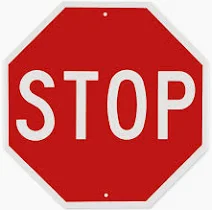

Below we give a possible solution. Don't let us spoil your fun.

In [ ]:
def unmet_preconditions(state, action):
    """The preconditions of action that do not hold in state (empty if the action can be done)."""
    return [fact for fact in grounded_preconditions(action) if not state.get_value(fact).is_true()]


check(problem, parse_plan(reply, problem))

A verdict is enough to decide whether to *trust* a plan, but not much to *fix* it with. If a student hands in a wrong
plan, we do not just say "wrong", we say where and why. This is the idea behind **LLM-Modulo**
([Kambhampati et al., ICML 2024](https://arxiv.org/abs/2402.01817)): let the LLM *generate* candidate plans, let a
**sound checker** *test* each one and *critique* it in English, and send the critique back to the LLM.

⚒ **Task 8**: Write `critique(problem, plan, vocab)`. It returns `None` if the plan is valid. Otherwise it returns a short
English message about the *first* problem in the plan:

* the first action that cannot be done, its step number, and which of its preconditions do not hold at that point
  (use your `unmet_preconditions`), or,
* if all actions can be done, which goal facts do not hold at the end (`goal_atoms(problem)`).

Use the vocabulary to write facts and actions in English: `vocab.facts(list_of_facts)` and `vocab.action(action)`. For
example: *"Step 3, (stack b d), cannot be done: it requires that block d is clear, but that is not true at that point."*

**Important:** the notebook replays recorded LLM answers, so the next rounds of the loop work only if the critique is
worded exactly like ours. The solution below redefines `critique`, so running the cells in order always works.

In [ ]:
def critique(problem, plan, vocab=BLOCKS_VOCABULARY):
    """None if the plan is valid, otherwise a short explanation in English of what went wrong first."""
    return None  # your code here


print(critique(problem, parse_plan(reply, problem)))

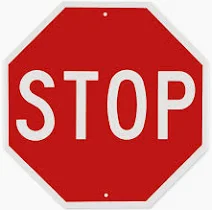

Below we give a possible solution. Don't let us spoil your fun.

In [ ]:
def critique(problem, plan, vocab=BLOCKS_VOCABULARY):
    """None if the plan is valid, otherwise a short explanation in English of what went wrong first."""
    with SequentialSimulator(problem) as simulator:
        state = simulator.get_initial_state()
        for step, action in enumerate(plan, start=1):
            unmet = unmet_preconditions(state, action)
            if unmet:
                return (f"Step {step}, {vocab.action(action)}, cannot be done: it requires that {vocab.facts(unmet)}, "
                        f"but that is not true at that point.")
            state = simulator.apply(state, action)
        unmet = [g for g in goal_atoms(problem) if not state.get_value(g).is_true()]
        if unmet:
            return f"After the last step, the goal is not reached: it is not true that {vocab.facts(unmet)}."
    return None


print(critique(problem, parse_plan(reply, problem)))

## LLM-Modulo: generate, test, critique

Now the loop. `llm_modulo` asks for a plan, checks it with `critique`, and if it is wrong, sends the critique back to the
LLM with its own plan, and asks again, up to `max_rounds` times. A plan leaves the loop only when the checker accepts it.
The LLM does not have to be right; it only has to be right *eventually*, and the checker makes sure that we notice when
it is.

In [ ]:
def feedback_prompt(first_prompt, reply, message, model=None):
    return f"""{first_prompt}

You previously wrote this plan:

[PLAN]
{plan_block(reply).strip()}
[PLAN END]

A plan checker found a problem with it. {message}

Please write a corrected plan for the same problem, between [PLAN] and [PLAN END], one action per line.{answer_instruction(model or MODEL_ID)}"""


def llm_modulo(problem, vocab=BLOCKS_VOCABULARY, example=(example_problem, example_plan), max_rounds=5, model=None):
    """Generate, test, critique. Returns a list with one record per round: dict(round=..., valid=..., n_actions=..., message=..., reply=...)."""
    first_prompt = planning_prompt(problem, vocab, *example, model=model)
    prompt = first_prompt
    history = []
    for round_ in range(max_rounds + 1):  # round 0 is direct planning, then up to max_rounds rounds of feedback
        reply = ask(prompt, model)
        try:
            plan = parse_plan(reply, problem)
            message = critique(problem, plan, vocab)
        except PlanParseError as error:
            plan, message = None, f"The plan could not be read: {error}."
        history.append(dict(round=round_, valid=message is None, n_actions=None if plan is None else len(plan), message=message, reply=reply))
        if message is None:
            break
        prompt = feedback_prompt(first_prompt, reply, message, model)
    return history


for record in llm_modulo(problem):
    print(record)

In [ ]:
MAX_ROUNDS = 5


def solved_by_round(histories, max_rounds=MAX_ROUNDS):
    """Fraction of problems solved within r rounds of feedback, for r = 0..max_rounds."""
    solved_at = [next((h["round"] for h in history if h["valid"]), None) for history in histories]
    return [sum(s is not None and s <= r for s in solved_at) / len(histories) for r in range(max_rounds + 1)]


blocks_histories = []
for problem in problems:
    history = llm_modulo(problem, max_rounds=MAX_ROUNDS)
    blocks_histories.append(history)
    status = f"solved in round {history[-1]['round']}" if history[-1]["valid"] else f"not solved after {MAX_ROUNDS} rounds"
    print(f"{problem.name}: {status}")

blocks_curve = solved_by_round(blocks_histories)
print("\nsolved within r rounds:", [f"{x:.0%}" for x in blocks_curve])

A plan that passes the checker is a plan the robot of tutorial 4.1 can carry out: `pick-up` and `unstack` are its
`pick_up` skill, `stack` its `stack`, `put-down` its `put_down`. The cell below takes the first four-block problem,
builds its towers on table `t2`, and runs a plan that the checker accepts through those skills. With the recorded
answers none of the LLM's plans passed within five rounds, so the plan executed is the one the loop would
have taken next: Fast Downward's, for the same problem (the LLM's last plan, and where the checker stopped it, are
printed for comparison).

In [ ]:
#@title Helper: build the problem's towers on table t2 and run the checked plan with tutorial 4.1's skills { display-mode: "form" }
import re as _re

def towers_of(problem):
    """The initial towers of a blocks problem (lists from bottom to top), from its ontable/on facts."""
    on, bottoms = {}, []
    for fact, value in problem.initial_values.items():
        if not value.bool_constant_value():
            continue
        if fact.fluent().name == "ontable":
            bottoms.append(str(fact.args[0]))
        elif fact.fluent().name == "on":
            on[str(fact.args[1])] = str(fact.args[0])  # on(x, y): x is on y, so y carries x
    towers = []
    for bottom in sorted(bottoms):
        tower = [bottom]
        while tower[-1] in on:
            tower.append(on[tower[-1]])
        towers.append(tower)
    return towers


TOWER_SPOTS = [(0.50, -0.18), (0.50, 0.0), (0.50, 0.18), (0.66, -0.10), (0.66, 0.10)]


def layout_for(problem, colors=("yellow", "blue", "green", "red")):
    """A scene with the problem's towers on table t2, one colour per block."""
    layout = {}
    blocks = sorted(str(o) for o in problem.all_objects if o.type.name == "block")
    color_of = dict(zip(blocks, colors))
    for tower, (x, y) in zip(towers_of(problem), TOWER_SPOTS):
        for k, block in enumerate(tower):
            layout[block] = (color_of[block], [x, y, 0.72 + BLOCK_HALF_HEIGHT + 2 * k * BLOCK_HALF_HEIGHT])
    return layout


def run_blocks_plan(problem, plan, camera="overview", scale=2):
    """Carry out a plan of the blocks domain (pick-up, unstack, stack, put-down) with tutorial 4.1's skills.
    Returns (success, frames)."""
    load_scene(layout_for(problem))
    settle(0.5)
    frames, ok = [], True
    for action in plan:
        name, args = action.action.name, [str(p) for p in action.actual_parameters if str(p) != "rob"]
        if name in ("pick-up", "unstack"):
            ok, new_frames = pick_up(args[0])
        elif name == "stack":
            ok, new_frames = stack(args[0], args[1])
        else:  # put-down
            ok, new_frames = put_down(args[0], "t2", sample_free_spot("t2", args[0]))
        frames += [f[::scale, ::scale] for f in new_frames]
        if not ok:
            print(f"  {name}({', '.join(args)}) failed")
            break
    return ok, frames


def goal_on_robot(problem):
    """Whether every on(x, y) of the goal holds in the simulator: x rests on y."""
    goals = _re.findall(r"on\((\w+), (\w+)\)", " ".join(str(g) for g in problem.goals))
    settle(0.3)
    return all(np.linalg.norm(data.body(x).xpos[:2] - data.body(y).xpos[:2]) < BLOCK_HALF_WIDTH
               and abs(data.body(x).xpos[2] - data.body(y).xpos[2] - 2 * BLOCK_HALF_HEIGHT) < 0.01 for x, y in goals)


shown_problem = next(p for p in problems if n_blocks(p) <= 4)
shown_history = blocks_histories[problems.index(shown_problem)]
llm_plan = shown_history[-1]
print(f"{shown_problem.name}: the LLM's last plan ({llm_plan['n_actions']} actions) was {'valid' if llm_plan['valid'] else 'rejected'}:",
      llm_plan["message"] or "it passes the checker")
if llm_plan["valid"]:
    shown_plan = parse_plan(llm_plan["reply"], shown_problem)
    print("executing the LLM's plan:")
else:
    shown_plan = fd_plans[problems.index(shown_problem)].actions  # Fast Downward's plan, computed with the problems above
    print("executing Fast Downward's plan for the same problem (the checker accepts it):")
print("  " + ", ".join(f"{a.action.name}({', '.join(str(p) for p in a.actual_parameters if str(p) != 'rob')})" for a in shown_plan))
start_time = time.time()
ok, frames = run_blocks_plan(shown_problem, shown_plan)
print(f"executed in {time.time() - start_time:.0f}s of computing; skills succeeded: {ok}; goal holds on the robot: {goal_on_robot(shown_problem)}")
show_video(frames, fps=20)

A success rate needs references. Fast Downward is the ceiling; for a floor, a random planner that only ever picks actions that can be done:

In [ ]:
def random_plan_success(problem, length, n_samples=200, seed=0):
    """How often a random plan of the given length reaches the goal. The random planner at least only picks applicable actions."""
    rng = random.Random(seed)
    successes = 0
    with SequentialSimulator(problem) as simulator:
        for _ in range(n_samples):
            state = simulator.get_initial_state()
            for _ in range(length):
                action, parameters = rng.choice(list(simulator.get_applicable_actions(state)))
                state = simulator.apply(state, action, parameters)
            successes += simulator.is_goal(state)
    return successes / n_samples


random_success = [random_plan_success(problem, len(fd_plan.actions)) for problem, fd_plan in zip(problems, fd_plans)]
for problem, p in zip(problems, random_success):
    print(f"{problem.name}: a random plan succeeds with probability {p:.1%}")

# a random planner that gets one new attempt per round: P(solved within r rounds) = 1 - (1 - p)^(r + 1)
random_curve = [sum(1 - (1 - p) ** (r + 1) for p in random_success) / len(problems) for r in range(MAX_ROUNDS + 1)]
print("\nrandom floor, solved within r rounds:", [f"{x:.1%}" for x in random_curve])

In [ ]:
import matplotlib.pyplot as plt


def plot_rounds(curves, title, points=None):
    """Success rate against rounds of feedback, with the ceiling (Fast Downward) and the floor (random plans) on the same axes.

    `points` (optional) maps a label to a single success rate at round 0: a condition with direct answers only, no feedback."""
    rounds = list(range(MAX_ROUNDS + 1))
    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    ax.axhline(1.0, color="tab:green", linestyle="--", label="Fast Downward (ceiling): 100% valid plans")
    ax.plot(rounds, random_curve, color="gray", linestyle=":", marker=".", label="random applicable actions, FD plan length (floor)")
    styles = [("tab:blue", "-", 13, 8), ("tab:orange", "--", 8, 5), ("tab:purple", "-", 13, 8), ("tab:red", "--", 8, 5)]
    for k, ((label, curve), (color, linestyle, square, dot)) in enumerate(zip(curves.items(), styles)):
        ax.plot(rounds, curve, color=color, linestyle=linestyle, marker="o", markersize=dot, label=f"{label}: LLM-Modulo")
        ax.plot([0], [curve[0]], color=color, marker="s", markersize=square, linestyle="none", label=f"{label}: direct planning (baseline, round 0)")
        ax.annotate(f"{curve[0]:.0%}", (0, curve[0]), textcoords="offset points", xytext=(12, 10 + 14 * k), color=color)
        ax.annotate(f"{curve[-1]:.0%}", (rounds[-1], curve[-1]), textcoords="offset points", xytext=(-14, 10 + 14 * k), color=color)
    for (label, value), (color, marker) in zip((points or {}).items(), [("tab:purple", "*"), ("tab:red", "P")]):
        ax.plot([0], [value], color=color, marker=marker, markersize=16, linestyle="none", label=f"{label}: direct planning only (no feedback rounds)")
        ax.annotate(f"{value:.0%}", (0, value), textcoords="offset points", xytext=(40, -4), color=color)
    ax.annotate(f"{random_curve[-1]:.1%}", (rounds[-1], random_curve[-1]), textcoords="offset points", xytext=(6, -12), color="gray")
    ax.set_xlabel("rounds of feedback from the critic (0 = direct planning)")
    ax.set_ylabel(f"fraction of the {len(problems)} problems solved")
    ax.set_ylim(-0.03, 1.08)
    ax.set_xticks(rounds)
    ax.set_xlim(-0.3, rounds[-1] + 0.6)
    ax.set_title(title)
    ax.legend(loc="center right", fontsize=8)
    ax.grid(alpha=0.3)
    plt.show()


plot_rounds({"Blocksworld": blocks_curve}, f"{MODEL_ID}: plans validated by UP, {len(problems)} problems")

**Feedback did not help at all: after 5 rounds of precise critique, the model still solved none of the 20 problems.** Fast Downward solves all of them, and even our random floor reaches 4.6% after 5 rounds (it gets lucky on the problems with very short plans). The LLM-Modulo curve of this model is flat at 0%, *below* the floor.

Why? Look at what the model does with the feedback. In 30 of the 100 rounds of feedback, it answered with *exactly* the same plan as in the previous round, as if the critique had not been there, and in 4 of the 20 problems it repeated its first plan in all 6 rounds. In the 70 rounds in which it did change the plan, the new plan got past the step that the critic had named only 17 times; 38 times it broke at the same step again, and 14 times even earlier. (You can read the full history of every problem in the results file that we save at the end.)

This is a 4-billion-parameter model that answers without thinking first, and the result should not be read as "LLM-Modulo does not work". With a larger model, the same loop does help: on 100 Blocksworld instances, GPT-4 alone solved 40%, 55% when it was looped with itself as the verifier, and 88% when the loop used a sound verifier (the VAL plan validator) instead ([Valmeekam, Marquez & Kambhampati, 2023](https://arxiv.org/abs/2310.08118)). The LLM as a verifier was the weak link: it produced 38 false positives out of 45. And the loop guarantees that whatever comes out is valid. But it is a clear illustration of what the loop does *not* guarantee: it guarantees soundness (no invalid plan gets out), not progress (that a valid plan will ever be found). A planner that is wrong all the time, wrapped in a perfect verifier, is a verifier that rejects everything.

Is it a matter of size? The same family has a model of the same size that was trained to **think before it answers**:
it writes a long reasoning trace first, and only then the plan. We recorded its answers too (each took minutes on a
laptop), and we also renamed every action, predicate and object to a meaningless word (**Mystery Blocksworld**) to see
what the models lean on.

In [ ]:
#@title Helper: Mystery Blocksworld { display-mode: "form" }
import re

# our own meaningless vocabulary: every predicate, action, type and object gets a new name
MYSTERY_NAMES = {
    # predicates
    "on": "wexes", "ontable": "dorvy", "clear": "glimmant", "handempty": "vantic", "holding": "brizzles",
    # actions
    "pick-up": "florp", "put-down": "quiddle", "stack": "brask", "unstack": "tumbrel",
    # the domain and the block type (the robot type keeps its name, it is never shown to the LLM)
    "blocks": "realm", "block": "thing",
    # objects
    "rob": "zorb", "a": "kip", "b": "mox", "c": "lune", "d": "tobe", "e": "rask", "f": "vell", "g": "dorn",
}


def mystify(pddl):
    """Rename every name in a PDDL string according to MYSTERY_NAMES (variables like ?x keep their names)."""
    return re.sub(r"(?<![\w?-])[a-z][\w-]*", lambda m: MYSTERY_NAMES.get(m.group(0), m.group(0)), pddl)


MYSTERY_DOMAIN = mystify(DOMAIN)
print(MYSTERY_DOMAIN)


MYSTERY_VOCABULARY = Vocabulary(
    intro="I am working with a set of objects. Here are the actions I can do. In each action, X and Y stand for objects.",
    templates={
        "vantic": "zorb is vantic",
        "brizzles": "zorb brizzles {0}",
        "dorvy": "{0} is dorvy",
        "wexes": "{0} wexes {1}",
        "glimmant": "{0} is glimmant",
    },
)

mystery_problems = [PDDLReader().parse_problem_string(MYSTERY_DOMAIN, mystify(pddl)) for pddl in PROBLEM_PDDLS]
mystery_example_problem = PDDLReader().parse_problem_string(MYSTERY_DOMAIN, mystify(EXAMPLE_PROBLEM))
mystery_example_plan = [
    make_action(mystery_example_problem, MYSTERY_NAMES[a.action.name], *[MYSTERY_NAMES[str(p)] for p in a.actual_parameters])
    for a in example_plan
]
mystery_example = (mystery_example_problem, mystery_example_plan)

# sanity check: the renamed problems are the same problems (Fast Downward's plans, renamed, are still valid)
for problem, fd_plan in zip(mystery_problems, fd_plans):
    renamed = [make_action(problem, MYSTERY_NAMES[a.action.name], *[MYSTERY_NAMES[str(p)] for p in a.actual_parameters]) for a in fd_plan.actions]
    assert is_valid(problem, renamed)

print(planning_prompt(mystery_problems[0], MYSTERY_VOCABULARY, *mystery_example))

In [ ]:
mystery_histories = []
for problem in mystery_problems:
    history = llm_modulo(problem, vocab=MYSTERY_VOCABULARY, example=mystery_example, max_rounds=MAX_ROUNDS)
    mystery_histories.append(history)
    status = f"solved in round {history[-1]['round']}" if history[-1]["valid"] else f"not solved after {MAX_ROUNDS} rounds"
    print(f"{problem.name}: {status}")

mystery_curve = solved_by_round(mystery_histories)
print("\nsolved within r rounds:", [f"{x:.0%}" for x in mystery_curve])

In [ ]:
THINKING_ROUNDS = [0]  # the thinking model answers each problem once: direct planning, no rounds of feedback


def run_direct(problems_, vocab, example, model):
    """Direct planning (round 0 of llm_modulo, no feedback) on every problem, with the length of the model's reasoning."""
    histories = []
    for problem, fd_plan in zip(problems_, fd_plans):
        start = len(CALL_LOG)
        history = llm_modulo(problem, vocab, example, max_rounds=0, model=model)
        for record, (_, key) in zip(history, CALL_LOG[start:]):
            entry = CACHE[key]
            record.update({k: entry.get(k) for k in ("thinking_tokens", "finished_thinking", "seconds", "batch_size")})
        histories.append(history)
        record = history[0]
        status = ("valid" if record["valid"] else "no answer (out of budget)" if not record["finished_thinking"]
                  else "no action in parentheses" if record["n_actions"] == 0 else "invalid")
        print(f"{problem.name}: {status:<25} plan {record['n_actions']:>2} actions (Fast Downward {len(fd_plan.actions):>2}), "
              f"{record['thinking_tokens']:>5} reasoning tokens, {record['seconds'] / 60:4.1f} min")
    return histories


def check_unparenthesized(problems_, histories):
    """For answers that contain no action in parentheses: would the plan be valid if each line were put in parentheses?"""
    for problem, history in zip(problems_, histories):
        record = history[0]
        if record["finished_thinking"] and record["n_actions"] == 0:
            lines = [line.strip() for line in plan_block(record["reply"]).splitlines() if line.strip()]
            plan = parse_plan("\n".join(f"({line})" for line in lines), problem)
            print(f"{problem.name}: {len(lines)} actions written without parentheses, for example {lines[0]!r}; "
                  f"put in parentheses, the plan is {'VALID' if is_valid(problem, plan) else 'INVALID'}")


thinking_blocks_histories = run_direct(problems, BLOCKS_VOCABULARY, (example_problem, example_plan), THINKING_MODEL)
thinking_blocks_curve = solved_by_round(thinking_blocks_histories, max_rounds=0)  # a single entry, for round 0
print(f"\nvalid plans: {sum(h[0]['valid'] for h in thinking_blocks_histories)} of {len(problems)} ({thinking_blocks_curve[0]:.0%})\n")
check_unparenthesized(problems, thinking_blocks_histories)

In [ ]:
thinking_mystery_histories = run_direct(mystery_problems, MYSTERY_VOCABULARY, mystery_example, THINKING_MODEL)
thinking_mystery_curve = solved_by_round(thinking_mystery_histories, max_rounds=0)
print(f"\nvalid plans: {sum(h[0]['valid'] for h in thinking_mystery_histories)} of {len(mystery_problems)} ({thinking_mystery_curve[0]:.0%})\n")
check_unparenthesized(mystery_problems, thinking_mystery_histories)

from collections import Counter
for label, histories in [("Blocksworld", thinking_blocks_histories), ("Mystery", thinking_mystery_histories)]:
    lengths = Counter(h[0]["n_actions"] for h in histories if h[0]["n_actions"])
    print(f"{label}: plan lengths of the non-empty answers (actions: how many answers): {dict(sorted(lengths.items()))}")
print(f"Fast Downward's plan lengths (actions: how many problems): {dict(sorted(Counter(len(p.actions) for p in fd_plans).items()))}")

In [ ]:
plot_rounds({"Instruct, Blocksworld": blocks_curve, "Instruct, Mystery": mystery_curve},
            f"Qwen3-4B, Instruct vs Thinking: plans validated by UP, {len(problems)} problems",
            points={"Thinking, Blocksworld": thinking_blocks_curve[0], "Thinking, Mystery": thinking_mystery_curve[0]})

The Instruct model's curves (one point per round of feedback) and the thinking model's two points (direct planning only, no feedback) share the axes with the ceiling and the floor. Thinking lifted direct planning from 0% to **60% in Blocksworld**, but only to **15% in Mystery Blocksworld** (3 of 20), and the 3 mystery problems it solved are the three shortest ones, with plans of 2, 2 and 4 actions. Look also at the lengths of the mystery plans: 11 of the 15 non-empty answers have exactly 4 actions, the length of the example in the prompt, whatever the size of the problem. The Instruct model did the same. Reasoning made the model much better at a problem it recognizes, and much less so at the *same* problem in words it has never seen: the pattern of o1-preview (97.8% against 52.8%), on a much smaller scale.

Keep the noise in mind: every answer of the thinking model is one random sample, so a different seed would move these numbers by a few problems. A gap of 60% against 15%, or 60% against 0%, is far larger than that.

In [ ]:
for label, histories, problems_, vocab, example in [
        ("Blocksworld", thinking_blocks_histories, problems, BLOCKS_VOCABULARY, (example_problem, example_plan)),
        ("Mystery", thinking_mystery_histories, mystery_problems, MYSTERY_VOCABULARY, mystery_example)]:
    traces = [CACHE[cache_key(THINKING_MODEL, planning_prompt(p, vocab, *example, model=THINKING_MODEL))]["thinking"] for p in problems_]
    gave_up = [p.name for p, t in zip(problems_, traces) if "give up" in t.lower()]
    print(f"{label}: {len(gave_up)} of {len(traces)} traces say 'give up' somewhere: {gave_up}")

# the end of the reasoning on one mystery problem
i = 9
entry = CACHE[cache_key(THINKING_MODEL, planning_prompt(mystery_problems[i], MYSTERY_VOCABULARY, *mystery_example, model=THINKING_MODEL))]
print(f"\n{mystery_problems[i].name}, the last lines of {entry['thinking_tokens']} tokens of reasoning:\n")
print(entry["thinking"][-900:])
print(f"\nThe critic: {thinking_mystery_histories[i][0]['message']}")

In Mystery Blocksworld, half of the traces (10 of 20) contain the words "give up", against 3 of 20 in Blocksworld. The trace above ends like this:

> I give up. I'll write the following plan based on the example: [...] Even though (florp tobe) might not be valid, it's the closest I can get.

The model *knew* that its plan was probably wrong, and handed it in anyway, adapted from the example. The answer itself gives no sign of this doubt: it is a clean plan between `[PLAN]` and `[PLAN END]`, like every other answer. Only the validator tells us (step 3, `(florp tobe)`, cannot be done). This is the copying of the example's shape that we saw in the Instruct model's mystery plans, this time written out in words.

❓ **The LLM-Modulo loop guarantees that every plan that leaves it is valid. What does it *not* guarantee? And who wrote
the model that the checker checks against?**

# ★ Following one patch through the network

Tasks 5 and 6 looked at the end of the journey. Here is all of it, stage by stage, with tensors you can print, for the
same image and the same block. The picture to keep in mind:

```
3 camera images ─┐  256x256 → 512x512 → 32x32 patches → SigLIP → 4x4 merge → 64 tokens per image ┐
instruction ─────┼─ "put the red block on the blue block" → up to 48 word tokens, padded to 48 ────┤ prefix: 241 tokens
joint angles ────┘  7 numbers → 1 state token ─────────────────────────────────────────────────────┘      │ keys, values
                                                                                                          ▼
                     50 noisy actions ─→ action expert (queries) ─→ 10 Euler steps of flow ─→ 50 joint targets
```

## Stage 1: pixels to patches

SmolVLA's vision encoder, **SigLIP**, expects 512x512 images with values in $[-1, 1]$. Our 256x256 images are scaled up
(they are square, so no padding is needed) and cut into a grid of **32 x 32 = 1024 patches** of 16 x 16 pixels. Every
patch is flattened and projected to a vector of 768 numbers: a **token**. From here on, the network never sees pixels
again, only these vectors. Our block's patch is at `patch` below (the 512x512 image is ours scaled by 2).

In [ ]:
batch = preprocess(policy_input(task))
pixel_images, _ = policy.prepare_images(batch)  # one (1, 3, 512, 512) tensor per camera, in the policy's camera order
order = camera_order(policy)
for name, image in zip(order, pixel_images):
    print(f"{name:>8}: {tuple(image.shape)}, values in [{image.min():.2f}, {image.max():.2f}]")

vlm = policy.model.vlm_with_expert.get_vlm_model()
with torch.no_grad():
    siglip_tokens = vlm.vision_model(pixel_values=pixel_images[order.index("front")].to(vlm.vision_model.dtype)).last_hidden_state
print("SigLIP output for the front camera:", tuple(siglip_tokens.shape), "= (batch, patches, features)")
patch = int(row * 2 // PATCH) * 32 + int(col * 2 // PATCH)
print(f"the block is in patch {patch} of 1024")
draw_patch_grid(images["front"])

## Stage 2: 1024 patches to 64 tokens

1024 tokens per image, three images, would make the language model very slow. The **connector** merges every 4 x 4 block
of neighbouring patches into one token (*pixel shuffle*: the 16 vectors of 768 numbers are concatenated into one of
12,288) and projects it to the 960 numbers that the language model works with. So **each token covers 64 x 64 pixels**
of the 512x512 image, 32 x 32 of ours: the square you highlighted in Task 5. Our block is about a quarter of a token.

In [ ]:
with torch.no_grad():
    shuffled = vlm.connector.pixel_shuffle(siglip_tokens, vlm.connector.scale_factor)
    image_tokens = vlm.connector.modality_projection(shuffled)
print("after pixel shuffle:", tuple(shuffled.shape), " after the projection:", tuple(image_tokens.shape))

# check where the patches go: mark the 16 patches of our token and see which merged token carries the mark
marked = torch.zeros(1, 1024, 1)
r0, c0 = divmod(token, 8)
for dr in range(4):
    for dc in range(4):
        marked[0, (4 * r0 + dr) * 32 + 4 * c0 + dc] = 1
merged = vlm.connector.pixel_shuffle(marked, 4)  # (1, 64, 16)
print("the marked patches all end up in token", merged.sum(-1).argmax().item(), "with", int(merged.sum()), "of 16 marks")

## Stage 3: the prefix, everything the robot knows right now

The three images become 3 x 64 = 192 tokens. The instruction is cut into word pieces by the language model's tokenizer
and padded to 48 tokens. The 7 numbers of the state go through one linear layer and become a single token. Together,
**241 tokens**: the *prefix*, which the 16 layers of the VLM process with ordinary self-attention.

In [ ]:
for name, positions in layout_of_prefix.items():
    print(f"{name:>8}: positions {positions.start:3d} to {positions.stop - 1:3d}")
tokens = batch["observation.language.tokens"][0]
print("\nthe instruction, as the model reads it:", [policy.model.vlm_with_expert.processor.tokenizer.decode(t) for t in tokens if t != 0][:20])
print(f"\n{len(prefix_attention)} VLM layers, each (heads, 241 queries, 241 keys): {tuple(prefix_attention[0].shape)}")

## Stage 4: queries, keys and values

This is the attention of Task 5: the 50 action queries over the 241 prefix keys.

## Stage 5: from attention to motion, ten flow steps

The output of attention, weights times values, flows on through the action expert's layers, and comes out as a
**velocity** for the 50 noisy actions, exactly like Part 1's `FlowPolicy`. Ten Euler steps carry pure noise to a chunk
of joint targets. (SmolVLA runs time the other way round from Part 1: noise at $t = 1$, actions at $t = 0$.) Let's
watch the chunk take shape:

In [ ]:
flow_log = []
act_and_log_attention(policy, preprocess, postprocess, task)
steps_, log = flow_log, None
flow_log = None
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2), sharey=True)
for ax, k in zip(axes, [0, 3, 6, len(steps_) - 1]):
    t, x = steps_[k]
    ax.plot(x[:, :6])
    ax.set_title(f"t = {t:.1f}" + (" (noise)" if k == 0 else " (the chunk)" if k == len(steps_) - 1 else ""))
    ax.set_xlabel("action in the chunk (0.1 s each)")
axes[0].set_ylabel("joint targets (normalized)")
plt.tight_layout()
plt.show()

At $t = 1$ the six curves are noise; after ten steps they are six smooth joint trajectories for the next five seconds.
We execute the first ten of them, look again, and generate a new chunk: the receding horizon of Part 1, ten times bigger.

# ★ Extras

## ★ Fine-tune it yourself

The policy you used was fine-tuned for 20,000 steps on a large GPU. You can fine-tune the pretrained SmolVLA on
the same demonstrations yourself; on a T4, `SETTINGS["finetune_steps"]` steps take about a quarter of an hour. Watch the
loss, then evaluate your policy on a few tasks with `evaluate`. How does it compare with the curve above?

In [ ]:
import sys

# the kernel's own Python: works whether or not this environment's bin/ is on the PATH
!{sys.executable} -m lerobot.scripts.lerobot_train --policy.path=lerobot/smolvla_base --policy.device={DEVICE} --policy.push_to_hub=false \
  --dataset.repo_id=local/rpa-wed-stack --dataset.root={DATA_DIR}/ds2 \
  --rename_map='{json.dumps(RENAME_MAP)}' \
  --batch_size={SETTINGS["batch_size"]} --steps={SETTINGS["finetune_steps"]} --save_freq={SETTINGS["finetune_steps"]} \
  --num_workers=2 --wandb.enable=false --output_dir=my_smolvla --job_name=my_smolvla

In [ ]:
mine = load_policy(f"my_smolvla/checkpoints/last/pretrained_model")
rate, outcomes = evaluate(*mine, seeds=range(5))
print(f"success on 5 new tasks: {rate:.0%}")

## ★ A long horizon: let the planner sequence the skill

Our policy learned one thing: put one block on another. Ask it for a tower of three, in one instruction, and it has no
idea (try it). But tutorial 4.1 already knows how to break a tower into steps. Let Fast Downward plan, and give each `stack`
of the plan to the policy as an instruction: the **planner** owns the long horizon, the **learned skill** owns the
motion. This is the division of labour that the lecture argued for.

In [ ]:
layout, _, _, _ = random_task(np.random.default_rng([2, 0]))
load_scene(layout)
bottom, middle, top = list(layout)
problem = make_problem(estimate_state(), f"(and (on {middle} {bottom}) (on {top} {middle}))")
for action in solve(problem):
    if action.action.name == "stack":
        block, onto = (str(p) for p in action.actual_parameters)
        instruction = f"put the {BLOCK_COLORS[block]} block on the {BLOCK_COLORS[onto]} block"
        print("planner says:", action, "-> policy is told:", instruction)
        frames, _ = run_policy(policy, preprocess, postprocess, instruction, max_seconds=20)
        show_video(frames, fps=5)
print(sorted(estimate_state()))

★ **More:** the per-layer attention (`prefix_attention`, one entry per VLM layer): how do the image tokens attend to the
words?

# What we did not get into

We saw only a corner of learning for robots. Among the things we left out:

* **Learning the model itself.** Parts 1 and 2 learned a *policy*, a map from what the robot sees to what it does. The
  other route is to learn a **world model**, $f(s, a) \to s'$: what happens if I do this, which a planner can then search
  over, as in tutorials 1.1 to 4.1, without a person writing the model down. *Dreamer* (Hafner et al., 2020-2025) learns
  one from pixels and trains a policy inside it; *V-JEPA 2* (Assran et al., 2025) learns one from video and plans with it.
* **The LLM as a translator.** Instead of planning (Part 3), the LLM can translate the request from English into
  a PDDL goal and let Fast Downward plan (*LLM+P*, Liu et al., 2023). The check stays where it was.
* **Thinking models, and what thinking costs.** In Part 3, the thinking model planned much better while the names
  meant something; each of its answers took minutes.
* **Checking a learned policy.** The collision checker can test a flow policy's sampled chunks before the robot moves,
  and reject the ones that collide, as LLM-Modulo did with plans. Nothing like that exists yet for SmolVLA's chunks.
* **Scale.** SmolVLA was pretrained on about 23,000 recordings; $\pi_0$ (Black et al., 2024) on far more, from many robots.
  How much of a new robot can you download, and how many demonstrations does the rest cost?

If you want to read on, *Diffusion Policy* (Chi et al., RSS 2023) and the $\pi_0$ paper are good places to start.

# What have we done and what comes next?

In this tutorial we took the system of tutorials 1.1 to 4.1 apart and learned it back, one level at a time. In Part 1 a
policy cloned from the planner's demonstrations averaged two right ways around an obstacle into a wrong one, and a
flow-matching policy, with the loss you wrote, kept both. In Part 2 SmolVLA, fine-tuned on tutorial 4.1's own
demonstrations, stacked the right block on 26 of 50 new tasks from three cameras and a sentence, and we looked at where
it attends: fine-tuning taught it where the blocks are, not which one the instruction means. In Part 3 an LLM writes
plans in the right format and almost never a valid one, and a checker you write catches each one.

At every level the learned version needed **data**, made by the hand-written system, and lost a **check**. Where we could
keep one, the planner sequencing the learned skill, or the checker around the LLM, the combination was better than either
part alone.

Classical AI assumes the model; robotics has to get it. Today's bet is that you can download most of it and pay the rest
in demonstrations.

On the last day we take this question to a real robot, the TurtleBot: a high-level action, *push the ball from A to B*,
that someone has to turn into motion.